In [1]:
# tb_amp_env
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve


import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime
from torch.utils.tensorboard import SummaryWriter
import optuna

import random
import numpy as np
import torch

from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, confusion_matrix
import numpy as np
import time

from torch.utils.data import Dataset, DataLoader, random_split


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


/mnt/storageG1/lwang/miniconda3/envs/tb_amp_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
import random
import numpy as np

# If using PyTorch
import torch

# If using TensorFlow

# Optional: If using Python hash-based functions
os.environ["PYTHONHASHSEED"] = "42"

# Set seed for base Python random
random.seed(42)

# Set seed for NumPy
np.random.seed(42)

# Set seed for PyTorch (CPU and GPU)
torch.manual_seed(42)
torch.cuda.manual_seed(42)
torch.cuda.manual_seed_all(42)  # if using multi-GPU

# Force deterministic behavior in PyTorch
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [3]:

# # Manual FASTA parsing (without Biopython)
# fasta_path = "../data//naturalAMPs_APD2024a-ADAM.fasta.txt"

# # Read lines from the FASTA file
# with open(fasta_path, "r") as f:
#     lines = f.read().strip().splitlines()

# # Parse into (ID, Sequence) pairs
# records = []
# current_id = None
# current_seq = []
# for line in lines:
#     if line.startswith(">"):
#         if current_id is not None:
#             records.append([current_id, ''.join(current_seq)])
#         current_id = line[1:].strip()
#         current_seq = []
#     else:
#         current_seq.append(line.strip())

# # Add the last record
# if current_id is not None:
#     records.append([current_id, ''.join(current_seq)])

# # Convert to DataFrame
# df_fasta_manual = pd.DataFrame(records, columns=["Peptide ID", "Sequence"])
# df_fasta_manual.to_csv("../data/naturalAMPs_APD2024a-ADAM.csv", index=False)


# Manual FASTA parsing (without Biopython)
# fasta_path = "../data/uniprotkb_length_10_TO_80_NOT_antimicro_2025_04_14.fasta"

# # Read lines from the FASTA file
# with open(fasta_path, "r") as f:
#     lines = f.read().strip().splitlines()

# # Parse into (ID, Sequence) pairs
# records = []
# current_id = None
# current_seq = []
# for line in lines:
#     if line.startswith(">"):
#         if current_id is not None:
#             records.append([current_id, ''.join(current_seq)])
#         current_id = line[1:].strip()
#         current_seq = []
#     else:
#         current_seq.append(line.strip())

# # Add the last record
# if current_id is not None:
#     records.append([current_id, ''.join(current_seq)])

# # Convert to DataFrame
# df_fasta_manual = pd.DataFrame(records, columns=["Peptide ID", "Sequence"])
# df_fasta_manual.to_csv("../data/uniprotkb_length_10_TO_80_NOT_antimicro_2025_04_14.fasta.csv", index=False)



# fasta_path = "../data/uniprotkb_length_5_TO_30_NOT_antimicrob_2025_04_14.fasta (1)"

# # Read lines from the FASTA file
# with open(fasta_path, "r") as f:
#     lines = f.read().strip().splitlines()

# # Parse into (ID, Sequence) pairs
# records = []
# current_id = None
# current_seq = []
# for line in lines:
#     if line.startswith(">"):
#         if current_id is not None:
#             records.append([current_id, ''.join(current_seq)])
#         current_id = line[1:].strip()
#         current_seq = []
#     else:
#         current_seq.append(line.strip())

# # Add the last record
# if current_id is not None:
#     records.append([current_id, ''.join(current_seq)])

# # Convert to DataFrame
# df_fasta_manual = pd.DataFrame(records, columns=["Peptide ID", "Sequence"])
# df_fasta_manual.to_csv("../data/uniprotkb_length_10_TO_80_NOT_antimicro_2025_04_14.fasta1.csv", index=False)

## Data

In [4]:
# from Bio import SeqIO

# def read_fasta_sequences(fasta_path):
#     """
#     Reads sequences from a FASTA file and returns them as a list of strings.

#     Args:
#         fasta_path (str): Path to the FASTA file.

#     Returns:
#         List[str]: A list of amino acid or nucleotide sequences as strings.
#     """
#     sequences = [str(record.seq) for record in SeqIO.parse(fasta_path, "fasta")]
#     return sequences

In [5]:
dbbasp = pd.read_csv("../data/DBAASP_peptides.csv")
dbbasp = dbbasp[dbbasp["SEQUENCE"].str.len() >= 10]
dbbasp = dbbasp[~dbbasp["TARGET GROUP"].str.contains("Fungus", na=False)]
dbbasp = dbbasp[["ID", "SEQUENCE"]]
dbbasp.columns = ["Peptide ID", "Sequence"]
adam_df = pd.read_csv("../data/naturalAMPs_APD2024a-ADAM.csv")
adam_df = pd.concat([adam_df, dbbasp], ignore_index=True)
uniprot_df = pd.read_csv("../data/uniprotkb_length_10_TO_80_NOT_antimicro_2025_04_14.fasta.csv")
uniprot_df1 = pd.read_csv("../data/uniprotkb_length_10_TO_80_NOT_antimicro_2025_04_14.fasta1.csv")
uniprot_df2 = pd.read_csv("/mnt/storageG1/lwang/Projects/TB-AMP-design/data/uniprotkb_length_5_TO_30_NOT_antimicrob_2025_04_23 (1).tsv", sep="\t")
uniprot_df2
uniprot_df2 = uniprot_df2[['Entry', 'Sequence']]
uniprot_df2.columns = ["Peptide ID", "Sequence"]
uniprot_df = pd.concat([uniprot_df, uniprot_df1, uniprot_df2], ignore_index=True)

In [6]:
adam_df.shape

(22202, 2)

In [7]:
uniprot_df.shape

(106370, 2)

In [8]:
uniprot_df = uniprot_df[uniprot_df['Sequence'].apply(lambda s: isinstance(s, str) and len(s) >= 10)]
uniprot_df = uniprot_df.drop_duplicates(subset="Sequence")
uniprot_df

,Peptide ID,Sequence
0,tr|A0A009HCC0|A0A009HCC0_9GAMM Acyl carrier pr...,MSDIEQRVKQAVAEQLGLKAEEIKNEASFMDDLGADSLDLVELVMS...
6,tr|A0A009YF97|A0A009YF97_9GAMM Acyl carrier pr...,MSDIEQRVKQAVAEQLGMKVEEIKNEASFMDDLGADSLDLVELVMS...
8,tr|A0A010SZ96|A0A010SZ96_PSEFL Acyl carrier pr...,MSTIEERVKKIVAEQLGVKEEEVVNTASFVEDLGADSLDTVELVMA...
9,tr|A0A011NAB1|A0A011NAB1_9PAST Acyl carrier pr...,MSIEERVKKIIVDQLGAKAEDVKPEASFIEDLGADSLDTVELVMAL...
10,tr|A0A011NTH9|A0A011NTH9_9PROT DNA-directed RN...,MARVTVDDCLTRIPNRFQMTLAATYRARQITAGASPLIDANRDKPT...
...,...,...
104968,P9WEJ1,MPEQKANCSPNGNITVDSMIMSLGSS
105566,Q6LEB3,LFNKYISRPRRVELAVMLNLTERHIKI
105568,Q6QLL8,VKGFSFKYGNGVWIGRTKSTNSRSGFQ
105789,Q9DTV7,HFPGFGQSLLFGYPVYVFGDCVQGDWCR


In [9]:

# Remove rows where the Sequence is not a string or is shorter than 10 characters
adam_df = adam_df[adam_df['Sequence'].apply(lambda x: isinstance(x, str) and len(x) >= 10)]

190 10
Range of sequence lengths: 180


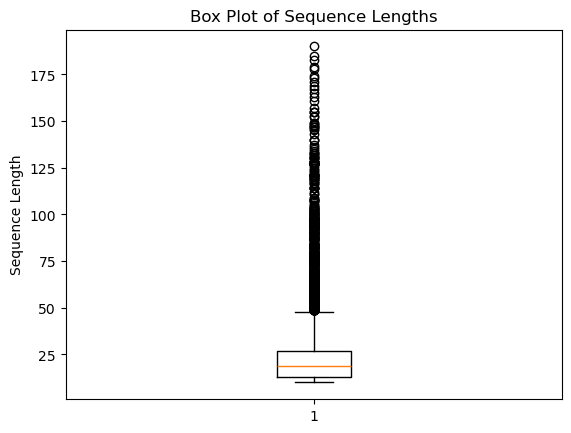

Mean sequence length: 23.215054249547922
Median sequence length: 19.0
Standard deviation of sequence lengths: 15.467236594870446


In [10]:
import matplotlib.pyplot as plt

# Calculate sequence lengths
sequence_lengths = adam_df['Sequence'].apply(len)

# Calculate the range of sequence lengths
length_range = sequence_lengths.max() - sequence_lengths.min()
print(sequence_lengths.max(),sequence_lengths.min())
print(f"Range of sequence lengths: {length_range}")

# Draw a box plot
plt.boxplot(sequence_lengths)
plt.title("Box Plot of Sequence Lengths")
plt.ylabel("Sequence Length")
plt.show()

# Calculate and display distribution statistics
mean_length = sequence_lengths.mean()
median_length = sequence_lengths.median()
std_dev_length = sequence_lengths.std()

print(f"Mean sequence length: {mean_length}")
print(f"Median sequence length: {median_length}")
print(f"Standard deviation of sequence lengths: {std_dev_length}")

# adam_df = adam_df.drop(columns=['Sequence Length'])

/tmp/ipykernel_62247/679251586.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_uniprot_df = uniprot_df.groupby('Sequence Length', group_keys=False).apply(


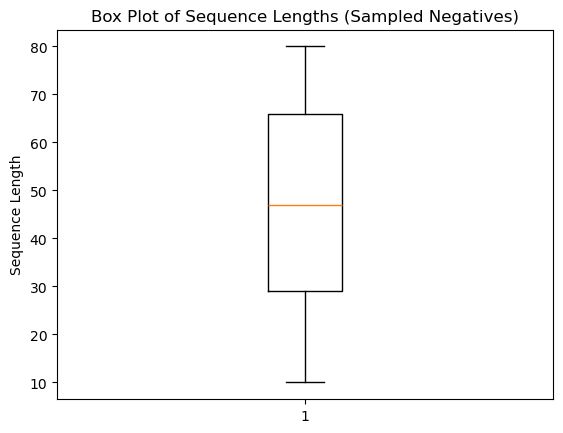

                                              Peptide ID  \
0      sp|C0HJE2|AMYG_BACLI Glucoamylase (Fragment) O...   
1      sp|Q03367|PSBF_CAPAN Cytochrome b559 subunit b...   
2      sp|Q10997|SPI_HALRO Serine proteinase inhibito...   
3      sp|P85962|RLA2_PSEMZ Large ribosomal subunit p...   
4      sp|P02728|GLEM_HUMAN Erythrocyte membrane glyc...   
...                                                  ...   
15376  tr|A0A497J933|A0A497J933_9ARCH DNA-directed RN...   
15377  tr|Q6Q0P4|Q6Q0P4_POLCT Cytochrome c oxidase su...   
15378  tr|A0A2J4G6H0|A0A2J4G6H0_9CREN DNA-directed RN...   
15379  tr|A0A327J0Z7|A0A327J0Z7_9BACT ATP synthase su...   
15380  tr|A0A0G2F2K3|A0A0G2F2K3_PHACM U6 snRNA-associ...   

                                                Sequence  
0                                             SSNKLTTSWG  
1                                             SISAMQFIQR  
2                                             TKKDGEEKVA  
3                                          

In [11]:
# Calculate sequence lengths for uniprot_df
uniprot_df['Sequence Length'] = uniprot_df['Sequence'].apply(len)

# Calculate sequence lengths for adam_df
adam_df['Sequence Length'] = adam_df['Sequence'].apply(len)

# Perform stratified sampling to select more samples
default_min_samples = 30

# Perform lenient stratified sampling
sampled_uniprot_df = uniprot_df.groupby('Sequence Length', group_keys=False).apply(
    lambda x: x.sample(
        n=min(
            len(x), 
            int(14 * adam_df['Sequence Length'].value_counts().get(x.name, default_min_samples))
        ),
        random_state=42
    )
).reset_index(drop=True)
# Drop the 'Sequence Length' column after sampling
sampled_uniprot_df = sampled_uniprot_df.drop(columns=['Sequence Length'])
adam_df = adam_df.drop(columns=['Sequence Length'])

# Draw a box plot to visualize the distribution
plt.boxplot(sampled_uniprot_df['Sequence'].apply(len))
plt.title("Box Plot of Sequence Lengths (Sampled Negatives)")
plt.ylabel("Sequence Length")
plt.show()

print(sampled_uniprot_df)

### data organization

In [12]:
adam_df['label'] = 1
sampled_uniprot_df['label'] = 0
adam_df.columns = ["Peptide ID", "Sequences", 'label']
sampled_uniprot_df.columns = ["Peptide ID", "Sequences" , 'label']
df = pd.concat([adam_df, sampled_uniprot_df], ignore_index=True)

max_length = df['Sequences'].str.len().max()
print(max_length)
# df['Sequences'] = df['Sequences'].apply(lambda x: x.ljust(max_length, 'X'))

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWYX")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)

# Filter out sequences containing non-standard amino acids
df = df[~df['Sequences'].str.contains('|'.join(non_standard_amino_acids))]
df = df.drop_duplicates(subset='Sequences')
tb_df = pd.read_csv('../data/all_seq702.csv')
df = df[~df['Sequences'].isin(tb_df['Sequences'])]
df = df[df['Sequences'].apply(lambda x: isinstance(x, str) and len(x) >= 10)]
print(f"Number of sequences after filtering: {len(df)}")
print(df['label'].value_counts())

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWYX")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)

X = df["Sequences"]
y = df["label"]

# Split into train (70%), validation (15%), test (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 2: Split train+val into train and val (stratified)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)  # 0.1765 to maintain 15% of original dataset




190
{'S', 'K', 'h', 'O', 'C', '9', 'Z', 'E', 'F', 'k', 'V', 'D', 'U', 'A', 'T', 't', 'B', 'g', 'a', 'y', ' ', 'I', 'v', 'X', 'w', 'H', 'M', 'm', 'Q', 'r', 'p', 'q', 'l', 'W', 'd', 'G', 'P', 's', 'n', 'e', 'R', 'c', 'L', 'x', 'i', 'Y', 'N', 'f'}
48
{'9', 'h', 'O', 'Z', 'k', 'U', 't', 'B', 'g', 'y', ' ', 'v', 'w', 'm', 'p', 'r', 'q', 'l', 'd', 's', 'n', 'e', 'c', 'x', 'i', 'a', 'f'}
Number of sequences after filtering: 30987
label
1    15839
0    15148
Name: count, dtype: int64
{'S', 'K', 'C', 'E', 'F', 'V', 'D', 'A', 'T', 'I', 'X', 'H', 'M', 'Q', 'W', 'G', 'P', 'R', 'L', 'Y', 'N'}
21
set()


In [13]:
y_test.value_counts()

label
1    2376
0    2272
Name: count, dtype: int64

In [14]:
# lengths = [len(seq) for seq in df['Sequences']]
# print(lengths[lengths <= 0])

lengths = np.array([len(seq) for seq in df['Sequences']])
print(lengths[lengths <= 0])


[]


### dataset

In [15]:

# Define One-Hot Encoding Function for DNA Sequences in PyTorch
def one_hot_torch(seq: str, dtype=torch.float32):
    amino_acids = "ACDEFGHIKLMNPQRSTVWY"
    seq_bytes = torch.ByteTensor(list(bytes(seq, "utf-8")))
    aa_bytes = torch.ByteTensor(list(bytes(amino_acids, "utf-8")))
    arr = torch.zeros(len(amino_acids), len(seq_bytes), dtype=dtype)
    for i, aa in enumerate(aa_bytes):
        arr[i, seq_bytes == aa] = 1
    return arr


class SequenceDataset(Dataset):
    def __init__(self, sequences, labels, one_hot_dtype=torch.float32):
        self.sequences = sequences
        self.labels = labels
        self.one_hot_dtype = one_hot_dtype

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        seq = self.sequences.iloc[idx]
        label = self.labels.iloc[idx]
        length = len(seq.replace("X", ""))  # unpadded length
        return one_hot_torch(seq, dtype=self.one_hot_dtype), torch.tensor(label, dtype=torch.float32), length

from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

def collate_and_pack(batch):
    # batch = list of (tensor_seq, label, length)
    sequences, labels, lengths = zip(*batch)

    # Filter out sequences with zero length
    filtered_batch = [(seq, lbl, l) for seq, lbl, l in zip(sequences, labels, lengths) if l > 0]

    if len(filtered_batch) == 0:
        raise ValueError("All sequences in the batch have zero length.")

    sequences, labels, lengths = zip(*filtered_batch)

    # Convert lengths to tensor
    lengths = torch.tensor(lengths)

    # Sort by descending length (required by pack_padded_sequence)
    sorted_indices = torch.argsort(lengths, descending=True)
    sequences = [sequences[i] for i in sorted_indices]
    labels = torch.tensor([labels[i] for i in sorted_indices])
    lengths = lengths[sorted_indices]

    # Stack to shape: (batch_size, 20, seq_len) and transpose for LSTM input
    # LSTM expects input of shape (seq_len, batch_size, features)
    sequences = [seq.T for seq in sequences]  # Transpose each [20, L] to [L, 20]
    padded_seqs = pad_sequence(sequences, batch_first=False)  # shape: [max_len, batch, features]

    # Pack the sequence
    packed_input = pack_padded_sequence(padded_seqs, lengths.cpu(), batch_first=False)

    return packed_input, labels



In [16]:
# Define DataLoaders

train_dataset = SequenceDataset(X_train, y_train)
val_dataset = SequenceDataset(X_val, y_val)
test_dataset = SequenceDataset(X_test, y_test)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_and_pack)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)

    
# Display dataset sizes
dataset_sizes = {
    "Train": len(train_dataset),
    "Validation": len(val_dataset),
    "Test": len(test_dataset)
}
print("Dataset sizes:")
for name, size in dataset_sizes.items():
    print(f"{name}: {size}")

Dataset sizes:
Train: 21690
Validation: 4649
Test: 4648


## testing

In [17]:
import torch
import torch.nn as nn

class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=False,
            dropout=dropout if num_layers > 1 else 0
        )

        # Classifier
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        # packed_input: PackedSequence
        packed_output, (hn, cn) = self.lstm(packed_input)

        # hn: [num_layers, batch_size, hidden_dim]
        # We'll use the **last layer's** hidden state as feature
        last_hidden = hn[-1]  # shape: [batch_size, hidden_dim]

        # Fully connected + sigmoid
        out = self.fc(last_hidden)       # shape: [batch_size, 1]
        out = self.sigmoid(out).squeeze(1)  # shape: [batch_size]
        return out


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score

from torch.utils.tensorboard import SummaryWriter
import datetime

def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_loss = 1000.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_auc': []}

    # Set up TensorBoard writer
    log_dir = f"runs/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)

        # Run evaluation
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device)

        # Logging
        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        print(f"Epoch [{epoch}/{num_epochs}] - Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}, Val AUC: {val_auc:.4f}")

        # Save to history
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_auc'].append(val_auc)

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # torch.save(model.state_dict(), 'best_model.pt')

    writer.close()
    return history

from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, recall_score

def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)

    # Convert predicted probabilities to binary predictions
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]

    # Metrics
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    # Confusion matrix
    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)  # handle corner cases

    # Sensitivity and specificity
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        # Print metrics
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity (Recall for Positive Class): {sensitivity:.4f}")
        print(f"Specificity (Recall for Negative Class): {specificity:.4f}")

    return avg_loss, acc, auc


model = LSTMClassifier(hidden_dim=64)
history = train_model(model, train_loader, val_loader, num_epochs=10)


Epoch [1/10] - Train Loss: 0.5523, Val Loss: 0.6706, Val Acc: 0.5627, Val AUC: 0.7061
Epoch [2/10] - Train Loss: 0.4765, Val Loss: 0.3772, Val Acc: 0.8621, Val AUC: 0.9378
Epoch [3/10] - Train Loss: 0.3697, Val Loss: 0.3874, Val Acc: 0.7931, Val AUC: 0.9234
Epoch [4/10] - Train Loss: 0.2943, Val Loss: 0.2476, Val Acc: 0.9049, Val AUC: 0.9654
Epoch [5/10] - Train Loss: 0.2434, Val Loss: 0.2230, Val Acc: 0.9112, Val AUC: 0.9702
Epoch [6/10] - Train Loss: 0.2235, Val Loss: 0.2845, Val Acc: 0.8914, Val AUC: 0.9577
Epoch [7/10] - Train Loss: 0.2308, Val Loss: 0.1950, Val Acc: 0.9299, Val AUC: 0.9767
Epoch [8/10] - Train Loss: 0.1944, Val Loss: 0.1903, Val Acc: 0.9202, Val AUC: 0.9791
Epoch [9/10] - Train Loss: 0.1805, Val Loss: 0.1860, Val Acc: 0.9254, Val AUC: 0.9807
Epoch [10/10] - Train Loss: 0.1921, Val Loss: 0.1777, Val Acc: 0.9303, Val AUC: 0.9813


### adding in regularization

In [19]:
import torch
import torch.nn as nn

class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=False,
            dropout=dropout if num_layers > 1 else 0  # LSTM dropout applies only between layers
        )

        # Dropout after LSTM (even if 1 layer)
        self.dropout = nn.Dropout(dropout)

        # Fully connected classifier
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        packed_output, (hn, cn) = self.lstm(packed_input)

        # Get the last hidden state from the last layer
        last_hidden = hn[-1]  # shape: [batch_size, hidden_dim]

        # Apply dropout
        dropped = self.dropout(last_hidden)

        # Fully connected + sigmoid
        out = self.fc(dropped)       # shape: [batch_size, 1]
        out = self.sigmoid(out).squeeze(1)  # shape: [batch_size]
        return out


def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)  # L2 regularization

    best_val_loss = 1000.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_auc': []}

    # Set up TensorBoard writer
    log_dir = f"runs/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)   
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)

        # Run evaluation
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        # Logging
        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        print(f"Epoch [{epoch}/{num_epochs}] - "
              f"Train Loss: {avg_train_loss:.4f}, "
              f"Val Loss: {val_loss:.4f}, "
              f"Val Acc: {val_acc:.4f}, "
              f"Val AUC: {val_auc:.4f}")

        # Save to history
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_auc'].append(val_auc)

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model.pt')

    writer.close()
    return history



from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, recall_score

def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)

    # Convert predicted probabilities to binary predictions
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]

    # Metrics
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    # Confusion matrix
    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)  # handle corner cases

    # Sensitivity and specificity
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        # Print metrics
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity (Recall for Positive Class): {sensitivity:.4f}")
        print(f"Specificity (Recall for Negative Class): {specificity:.4f}")

    return avg_loss, acc, auc

model = LSTMClassifier(input_dim=20, hidden_dim=64, dropout=0.5)
history = train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3,
                      weight_decay=1e-4, verbose=True)



Confusion Matrix:
[[1786  487]
 [  74 2302]]
Sensitivity (Recall for Positive Class): 0.9689
Specificity (Recall for Negative Class): 0.7857
Epoch [1/10] - Train Loss: 0.4703, Val Loss: 0.3289, Val Acc: 0.8793, Val AUC: 0.9427

Confusion Matrix:
[[  12 2261]
 [   1 2375]]
Sensitivity (Recall for Positive Class): 0.9996
Specificity (Recall for Negative Class): 0.0053
Epoch [2/10] - Train Loss: 0.3643, Val Loss: 0.8430, Val Acc: 0.5134, Val AUC: 0.6575

Confusion Matrix:
[[1877  396]
 [ 438 1938]]
Sensitivity (Recall for Positive Class): 0.8157
Specificity (Recall for Negative Class): 0.8258
Epoch [3/10] - Train Loss: 0.6831, Val Loss: 0.6017, Val Acc: 0.8206, Val AUC: 0.8942

Confusion Matrix:
[[2173  100]
 [ 471 1905]]
Sensitivity (Recall for Positive Class): 0.8018
Specificity (Recall for Negative Class): 0.9560
Epoch [4/10] - Train Loss: 0.4295, Val Loss: 0.3204, Val Acc: 0.8772, Val AUC: 0.9526

Confusion Matrix:
[[2082  191]
 [ 212 2164]]
Sensitivity (Recall for Positive Class): 0

## Modelling on general AMP data (bayesian optimization)

### LSTM

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime


class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMClassifier, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=False,
            dropout=dropout if num_layers > 1 else 0
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        packed_output, (hn, cn) = self.lstm(packed_input)
        last_hidden = hn[-1]
        dropped = self.dropout(last_hidden)
        out = self.fc(dropped)
        out = self.sigmoid(out).squeeze(1)
        return out


def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    # if not train:
    #     model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm_.pt')

    writer.close()
    return best_val_loss



def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc


def objective(trial):
    hidden_dim = trial.suggest_int("hidden_dim", 32, 128)
    num_layers = trial.suggest_int("num_layers", 1, 3)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)
    lr = trial.suggest_float("lr", 1e-4, 1e-2)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2)

    model = LSTMClassifier(input_dim=20, hidden_dim=hidden_dim, num_layers=num_layers, dropout=dropout)
    val_auc = train_model(model, train_loader, val_loader, num_epochs=20, lr=lr,
                          weight_decay=weight_decay, verbose=False, train=True)
    return val_auc


study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)

print("Best hyperparameters:", study.best_trial.params)
lstm_best_param = study.best_trial.params

torch.onnx.export(model, input, "lstm.onnx", verbose=False, 
                 input_names=["input_names"], output_names=["output_names"],
                 export_params=True,)



/mnt/storageG1/lwang/miniconda3/envs/new-ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-04-29 17:33:07,537] A new study created in memory with name: no-name-f870dc5a-cf33-4209-8d39-e30a7224b46c
[I 2025-04-29 17:41:07,026] Trial 0 finished with value: 0.2616956039038423 and parameters: {'hidden_dim': 92, 'num_layers': 3, 'dropout': 0.14970413746911349, 'lr': 0.008962204396598826, 'weight_decay': 0.00038043632818235694}. Best is trial 0 with value: 0.2616956039038423.
[I 2025-04-29 17:47:32,932] Trial 1 finished with value: 0.6929274160568029 and parameters: {'hidden_dim': 35, 'num_layers': 2, 'dropout': 0.1466157950111399, 'lr': 0.0028233687762241493, 'weight_decay': 0.009838017482456001}. Best is trial 0 with value: 0.2616956039038423.
[I 2025-04-29 17:54:50,980] Trial 2 finished with value:

Best hyperparameters: {'hidden_dim': 95, 'num_layers': 1, 'dropout': 0.20287746211724011, 'lr': 0.004396992152527415, 'weight_decay': 3.999214064585909e-05}


#### testing

In [70]:
df = pd.read_csv('../data/all_seq702.csv')
df = df.drop_duplicates(subset='Sequences')
max_length = df['Sequences'].str.len().max()
print(max_length)
# df['Sequences'] = df['Sequences'].apply(lambda x: x.ljust(max_length, 'X'))

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)
b_count = df["Sequences"].str.count('B').sum()
print(f"Number of 'B' values: {b_count}")
# manually replaced one of the B with D and the other with N

df = df[
    (df['Sequences'].str.len() >= 10) &
    (df['Sequences'].apply(lambda x: len(set(x)) > 1)) &
    (~df['Sequences'].str.contains('X'))
]

X = df["Sequences"]
y = df["AMP"]


# Split into train (70%), validation (15%), test (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Step 2: Split train+val into train and val (stratified)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)  # 0.1765 to maintain 15% of original dataset

# Define DataLoaders


test_dataset = SequenceDataset(X_test, y_test)

batch_size = 32

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)

    
# Display dataset sizes
dataset_sizes = {
    "Train": len(train_dataset),
    "Validation": len(val_dataset),
    "Test": len(test_dataset)
}
print("Dataset sizes:")
for name, size in dataset_sizes.items():
    print(f"{name}: {size}")

128
{'E', 'X', 'H', 'M', 'P', 'T', 'N', 'V', 'G', 'L', 'A', 'K', 'F', 'Q', 'Y', 'C', 'W', 'S', 'I', 'R', 'D'}
21
{'X'}
Number of 'B' values: 0
Dataset sizes:
Train: 21690
Validation: 4649
Test: 88


In [107]:
test_loader

In [71]:
# model = LSTMClassifier(input_dim=20, hidden_dim=47, num_layers=2, dropout=0.18950252633567022)
# history = train_model(model, train_loader, val_loader, num_epochs=19, lr=0.009528266081905703,
#                       weight_decay=1.1052415577383506e-05, verbose=True)

model = LSTMClassifier(input_dim=20, hidden_dim=lstm_best_param['hidden_dim'], num_layers=lstm_best_param['num_layers'], dropout= lstm_best_param['dropout'])
history = train_model(model, train_loader, val_loader, num_epochs=20, lr=lstm_best_param['lr'],
                      weight_decay=lstm_best_param['weight_decay'], verbose=True)
criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

torch.save(model.state_dict(), 'best_model_lstm_1.pt')


Final Evaluation on Best Model:
Accuracy: 0.9273, AUC: 0.9780
Sensitivity: 0.9259, Specificity: 0.9287
Confusion Matrix:
[[2111  162]
 [ 176 2200]]
Epoch [1/20] - Train Loss: 0.4116, Val Loss: 13.8943, Val Acc: 0.9273, Val AUC: 0.9780

Final Evaluation on Best Model:
Accuracy: 0.9269, AUC: 0.9807
Sensitivity: 0.9579, Specificity: 0.8944
Confusion Matrix:
[[2033  240]
 [ 100 2276]]
Epoch [2/20] - Train Loss: 0.1918, Val Loss: 13.8834, Val Acc: 0.9269, Val AUC: 0.9807

Final Evaluation on Best Model:
Accuracy: 0.9325, AUC: 0.9835
Sensitivity: 0.9259, Specificity: 0.9393
Confusion Matrix:
[[2135  138]
 [ 176 2200]]
Epoch [3/20] - Train Loss: 0.1701, Val Loss: 13.8661, Val Acc: 0.9325, Val AUC: 0.9835

Final Evaluation on Best Model:
Accuracy: 0.9312, AUC: 0.9840
Sensitivity: 0.9108, Specificity: 0.9525
Confusion Matrix:
[[2165  108]
 [ 212 2164]]
Epoch [4/20] - Train Loss: 0.1601, Val Loss: 13.8805, Val Acc: 0.9312, Val AUC: 0.9840

Final Evaluation on Best Model:
Accuracy: 0.9381, AUC: 

In [73]:
import numpy as np
import contextlib
import os
import sys
import torch

# Helper: suppress stdout
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Metric containers
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMClassifier(input_dim=20, hidden_dim=lstm_best_param['hidden_dim'], num_layers=lstm_best_param['num_layers'], dropout= lstm_best_param['dropout'])

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=20,
            lr=lstm_best_param['lr'],
            weight_decay=lstm_best_param['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Manual calculation of sensitivity and specificity
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

    # Save model from the final run
    if run == n_runs - 1:
        torch.save(model.state_dict(), 'best_model_lstm_1.pt')

# Summary output
print("\n📊 Summary across 10 runs (Vanilla LSTM):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10

🔁 Run 2/10

🔁 Run 3/10

🔁 Run 4/10

🔁 Run 5/10

🔁 Run 6/10

🔁 Run 7/10

🔁 Run 8/10

🔁 Run 9/10

🔁 Run 10/10

📊 Summary across 10 runs (Vanilla LSTM):
Accuracy:       0.7977 ± 0.0445
AUC:            0.9381 ± 0.0174
Sensitivity:    0.9366 ± 0.0224
Specificity:    0.6766 ± 0.0730


### biLSTM

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime

class BiLSTMWithFlattenClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3, max_seq_len=100):
        super(BiLSTMWithFlattenClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.max_seq_len = max_seq_len

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(max_seq_len * hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        batch_size, seq_len, feature_dim = lstm_out.size()

        if seq_len < self.max_seq_len:
            pad_len = self.max_seq_len - seq_len
            pad = torch.zeros(batch_size, pad_len, feature_dim, device=lstm_out.device)
            lstm_out = torch.cat([lstm_out, pad], dim=1)
        elif seq_len > self.max_seq_len:
            lstm_out = lstm_out[:, :self.max_seq_len, :]

        dropped = self.dropout(lstm_out)
        flat = dropped.contiguous().view(batch_size, -1)
        out = self.fc(flat)
        return self.sigmoid(out).squeeze(1)

# Evaluation function
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc

# Training function
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000.0

    log_dir = f"runs-bilstm_flatten/BiLSTM_Flatten_Optuna_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model-bilstm.pt')

    writer.close()
    return best_val_loss

# Optuna objective function
def objective(trial):
    hidden_dim = trial.suggest_int("hidden_dim", 32, 128)
    num_layers = trial.suggest_int("num_layers", 1, 3)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)
    lr = trial.suggest_float("lr", 1e-4, 1e-2)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2)
    max_seq_len = 100  # fixed for now; match your padding/truncation

    model = BiLSTMWithFlattenClassifier(
        input_dim=20,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout,
        max_seq_len=max_seq_len
    )

    val_auc = train_model(
        model,
        train_loader,
        val_loader,
        num_epochs=10,
        lr=lr,
        weight_decay=weight_decay,
        verbose=False
    )
    return val_auc

# Usage (uncomment and run in your local environment):
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
print("Best hyperparameters:", study.best_trial.params)
bilstm_best_param = study.best_trial.params

[I 2025-04-29 19:29:40,503] A new study created in memory with name: no-name-d81b4d3d-c525-4f21-b95b-1d2a478f9d82


[I 2025-04-29 19:32:01,708] Trial 0 finished with value: 0.6928907338887045 and parameters: {'hidden_dim': 75, 'num_layers': 3, 'dropout': 0.42693865944872267, 'lr': 0.0020261333483325484, 'weight_decay': 0.005952273227183691}. Best is trial 0 with value: 0.6928907338887045.
[I 2025-04-29 19:34:36,224] Trial 1 finished with value: 0.20479340718625344 and parameters: {'hidden_dim': 128, 'num_layers': 3, 'dropout': 0.2182307095633875, 'lr': 0.005662073185742132, 'weight_decay': 0.0037388558223595586}. Best is trial 1 with value: 0.20479340718625344.
[I 2025-04-29 19:36:54,036] Trial 2 finished with value: 0.2191017038405758 and parameters: {'hidden_dim': 56, 'num_layers': 2, 'dropout': 0.2420715654472932, 'lr': 0.008023568972467593, 'weight_decay': 0.009494177308951385}. Best is trial 1 with value: 0.20479340718625344.
[I 2025-04-29 19:39:06,541] Trial 3 finished with value: 0.2220317884667279 and parameters: {'hidden_dim': 91, 'num_layers': 1, 'dropout': 0.25541069846604164, 'lr': 0.000

Best hyperparameters: {'hidden_dim': 59, 'num_layers': 1, 'dropout': 0.19595557432276017, 'lr': 0.009816503475479747, 'weight_decay': 2.600777275437832e-05}


In [74]:
bilstm_best_param = {'hidden_dim': 59, 'num_layers': 1, 'dropout': 0.19595557432276017, 'lr': 0.009816503475479747, 'weight_decay': 2.600777275437832e-05}

In [75]:
df = pd.read_csv('../data/all_seq702.csv')
df = df.drop_duplicates(subset='Sequences')
max_length = df['Sequences'].str.len().max()
print(max_length)
# df['Sequences'] = df['Sequences'].apply(lambda x: x.ljust(max_length, 'X'))

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)
b_count = df["Sequences"].str.count('B').sum()
print(f"Number of 'B' values: {b_count}")
# manually replaced one of the B with D and the other with N

df = df[
    (df['Sequences'].str.len() >= 10) &
    (df['Sequences'].apply(lambda x: len(set(x)) > 1)) &
    (~df['Sequences'].str.contains('X'))
]

X = df["Sequences"]
y = df["AMP"]


# Split into train (70%), validation (15%), test (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Step 2: Split train+val into train and val (stratified)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)  # 0.1765 to maintain 15% of original dataset

# Define DataLoaders


test_dataset = SequenceDataset(X_test, y_test)

batch_size = 32

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)

    
# Display dataset sizes
dataset_sizes = {
    "Train": len(train_dataset),
    "Validation": len(val_dataset),
    "Test": len(test_dataset)
}
print("Dataset sizes:")
for name, size in dataset_sizes.items():
    print(f"{name}: {size}")

128
{'E', 'X', 'H', 'M', 'P', 'T', 'N', 'V', 'G', 'L', 'A', 'K', 'F', 'Q', 'Y', 'C', 'W', 'S', 'I', 'R', 'D'}
21
{'X'}
Number of 'B' values: 0
Dataset sizes:
Train: 21690
Validation: 4649
Test: 88


In [76]:
# model = LSTMClassifier(input_dim=20, hidden_dim=47, num_layers=2, dropout=0.18950252633567022)
# history = train_model(model, train_loader, val_loader, num_epochs=19, lr=0.009528266081905703,
#                       weight_decay=1.1052415577383506e-05, verbose=True)
# to rerun
import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime

class BiLSTMWithFlattenClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3, max_seq_len=100):
        super(BiLSTMWithFlattenClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.max_seq_len = max_seq_len

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(max_seq_len * hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        batch_size, seq_len, feature_dim = lstm_out.size()

        if seq_len < self.max_seq_len:
            pad_len = self.max_seq_len - seq_len
            pad = torch.zeros(batch_size, pad_len, feature_dim, device=lstm_out.device)
            lstm_out = torch.cat([lstm_out, pad], dim=1)
        elif seq_len > self.max_seq_len:
            lstm_out = lstm_out[:, :self.max_seq_len, :]

        dropped = self.dropout(lstm_out)
        flat = dropped.contiguous().view(batch_size, -1)
        out = self.fc(flat)
        return self.sigmoid(out).squeeze(1)

# Evaluation function
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc

# Training function
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000.0

    log_dir = f"runs-bilstm_flatten/BiLSTM_Flatten_Optuna_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model-bilstm.pt')

    writer.close()
    return best_val_loss

model = BiLSTMWithFlattenClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout= bilstm_best_param['dropout'])
history = train_model(model, train_loader, val_loader, num_epochs=25, lr=bilstm_best_param['lr'],
                      weight_decay=bilstm_best_param['weight_decay'], verbose=True)
criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")


Confusion Matrix:
[[2181   92]
 [ 232 2144]]
Sensitivity: 0.9024, Specificity: 0.9595
Epoch [1/30] - Train Loss: 0.2150, Val Loss: 0.1871, Val Acc: 0.9303, Val AUC: 0.9842

Confusion Matrix:
[[2133  140]
 [ 148 2228]]
Sensitivity: 0.9377, Specificity: 0.9384
Epoch [2/30] - Train Loss: 0.1528, Val Loss: 0.1558, Val Acc: 0.9381, Val AUC: 0.9863

Confusion Matrix:
[[2108  165]
 [  86 2290]]
Sensitivity: 0.9638, Specificity: 0.9274
Epoch [3/30] - Train Loss: 0.1326, Val Loss: 0.1339, Val Acc: 0.9460, Val AUC: 0.9889

Confusion Matrix:
[[2069  204]
 [  49 2327]]
Sensitivity: 0.9794, Specificity: 0.9103
Epoch [4/30] - Train Loss: 0.1224, Val Loss: 0.1454, Val Acc: 0.9456, Val AUC: 0.9892

Confusion Matrix:
[[2166  107]
 [ 138 2238]]
Sensitivity: 0.9419, Specificity: 0.9529
Epoch [5/30] - Train Loss: 0.1138, Val Loss: 0.1338, Val Acc: 0.9473, Val AUC: 0.9896

Confusion Matrix:
[[2138  135]
 [ 109 2267]]
Sensitivity: 0.9541, Specificity: 0.9406
Epoch [6/30] - Train Loss: 0.1036, Val Loss: 0.1

In [78]:
import numpy as np
import contextlib
import os
import sys
import torch

# Helper: suppress stdout
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Run count
n_runs = 10

# Metric trackers
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = BiLSTMWithFlattenClassifier(
        input_dim=20,
        hidden_dim=bilstm_best_param['hidden_dim'],
        num_layers=bilstm_best_param['num_layers'],
        dropout=bilstm_best_param['dropout'],
        max_seq_len=100
    )

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=bilstm_best_param['lr'],
            weight_decay=bilstm_best_param['weight_decay'],
            verbose=False        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Manually calculate Sens/Spec
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Summary
print("\n📊 Summary across 10 runs (BiLSTM with Flatten):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10

🔁 Run 2/10

🔁 Run 3/10

🔁 Run 4/10

🔁 Run 5/10

🔁 Run 6/10

🔁 Run 7/10

🔁 Run 8/10

🔁 Run 9/10

🔁 Run 10/10

📊 Summary across 10 runs (BiLSTM with Flatten):
Accuracy:       0.8318 ± 0.0403
AUC:            0.9490 ± 0.0199
Sensitivity:    0.9683 ± 0.0156
Specificity:    0.7128 ± 0.0757


### lstm + attention

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime

# LSTM with Attention classifier
class LSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMWithAttentionClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=False
        )

        self.dropout = nn.Dropout(dropout)
        self.attn = nn.Linear(hidden_dim, 1)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)  # shape: [batch, seq_len, hidden_dim]

        # Compute attention weights
        attn_weights = self.attn(lstm_out).squeeze(-1)  # shape: [batch, seq_len]
        attn_weights = torch.softmax(attn_weights, dim=1)  # normalize
        attn_applied = torch.sum(lstm_out * attn_weights.unsqueeze(-1), dim=1)  # shape: [batch, hidden_dim]

        dropped = self.dropout(attn_applied)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)

# Evaluation function
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc

# Training function
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm-attn/LSTM_Attn_Optuna_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model-lstm_attention.pt')

    writer.close()
    return best_val_loss

# Optuna objective function
def objective(trial):
    hidden_dim = trial.suggest_int("hidden_dim", 32, 128)
    num_layers = trial.suggest_int("num_layers", 1, 3)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)

    model = LSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout
    )

    val_auc = train_model(
        model,
        train_loader,
        val_loader,
        num_epochs=10,
        lr=lr,
        weight_decay=weight_decay,
        verbose=False
    )
    return val_auc

# Usage
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
print("Best hyperparameters:", study.best_trial.params)
lstm_attn_best_param = study.best_trial.params

[I 2025-04-30 10:56:45,905] A new study created in memory with name: no-name-cb044d44-94a6-43ad-b244-f0c29d5a8dea


[I 2025-04-30 10:59:19,670] Trial 0 finished with value: 0.1714380279897827 and parameters: {'hidden_dim': 117, 'num_layers': 3, 'dropout': 0.17378063568060603, 'lr': 0.0009571318934944739, 'weight_decay': 9.93078411095272e-06}. Best is trial 0 with value: 0.1714380279897827.
[I 2025-04-30 11:01:43,899] Trial 1 finished with value: 0.2027659824449722 and parameters: {'hidden_dim': 115, 'num_layers': 1, 'dropout': 0.38266715758938774, 'lr': 0.0031185109363283145, 'weight_decay': 0.002949711204449274}. Best is trial 0 with value: 0.1714380279897827.
[I 2025-04-30 11:04:09,339] Trial 2 finished with value: 0.20427552069703195 and parameters: {'hidden_dim': 57, 'num_layers': 3, 'dropout': 0.25587002914485535, 'lr': 0.00011630774752681913, 'weight_decay': 1.106919812481162e-06}. Best is trial 0 with value: 0.1714380279897827.
[I 2025-04-30 11:06:53,693] Trial 3 finished with value: 0.19804924042665795 and parameters: {'hidden_dim': 103, 'num_layers': 3, 'dropout': 0.1479826371972119, 'lr': 

Best hyperparameters: {'hidden_dim': 85, 'num_layers': 1, 'dropout': 0.4548453210586073, 'lr': 0.005881852254528488, 'weight_decay': 1.22922875003128e-06}


In [79]:
df = pd.read_csv('../data/all_seq702.csv')
df = df.drop_duplicates(subset='Sequences')
max_length = df['Sequences'].str.len().max()
print(max_length)
# df['Sequences'] = df['Sequences'].apply(lambda x: x.ljust(max_length, 'X'))

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)
b_count = df["Sequences"].str.count('B').sum()
print(f"Number of 'B' values: {b_count}")
# manually replaced one of the B with D and the other with N

df = df[
    (df['Sequences'].str.len() >= 10) &
    (df['Sequences'].apply(lambda x: len(set(x)) > 1)) &
    (~df['Sequences'].str.contains('X'))
]

X = df["Sequences"]
y = df["AMP"]


# Split into train (70%), validation (15%), test (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Step 2: Split train+val into train and val (stratified)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)  # 0.1765 to maintain 15% of original dataset

# Define DataLoaders


test_dataset = SequenceDataset(X_test, y_test)

batch_size = 32

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)

    
# Display dataset sizes
dataset_sizes = {
    "Train": len(train_dataset),
    "Validation": len(val_dataset),
    "Test": len(test_dataset)
}
print("Dataset sizes:")
for name, size in dataset_sizes.items():
    print(f"{name}: {size}")

128
{'E', 'X', 'H', 'M', 'P', 'T', 'N', 'V', 'G', 'L', 'A', 'K', 'F', 'Q', 'Y', 'C', 'W', 'S', 'I', 'R', 'D'}
21
{'X'}
Number of 'B' values: 0
Dataset sizes:
Train: 21690
Validation: 4649
Test: 88


In [80]:
# model = LSTMClassifier(input_dim=20, hidden_dim=47, num_layers=2, dropout=0.18950252633567022)
# history = train_model(model, train_loader, val_loader, num_epochs=19, lr=0.009528266081905703,
#                       weight_decay=1.1052415577383506e-05, verbose=True)

import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime

# LSTM with Attention classifier
class LSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMWithAttentionClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=False
        )

        self.dropout = nn.Dropout(dropout)
        self.attn = nn.Linear(hidden_dim, 1)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)  # shape: [batch, seq_len, hidden_dim]

        # Compute attention weights
        attn_weights = self.attn(lstm_out).squeeze(-1)  # shape: [batch, seq_len]
        attn_weights = torch.softmax(attn_weights, dim=1)  # normalize
        attn_applied = torch.sum(lstm_out * attn_weights.unsqueeze(-1), dim=1)  # shape: [batch, hidden_dim]

        dropped = self.dropout(attn_applied)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)

# Evaluation function
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc

# Training function
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm-attn/LSTM_Attn_Optuna_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model-lstm_attention.pt')

    writer.close()
    return best_val_loss


# to rerun
model = LSTMWithAttentionClassifier(input_dim=20, hidden_dim=lstm_attn_best_param['hidden_dim'], num_layers=lstm_attn_best_param['num_layers'], dropout= lstm_attn_best_param['dropout'])
history = train_model(model, train_loader, val_loader, num_epochs=20, lr=lstm_attn_best_param['lr'],
                      weight_decay=lstm_attn_best_param['weight_decay'], verbose=True)
criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")


Confusion Matrix:
[[1906  367]
 [ 159 2217]]
Sensitivity: 0.9331, Specificity: 0.8385
Epoch [1/20] - Train Loss: 0.4392, Val Loss: 0.2941, Val Acc: 0.8869, Val AUC: 0.9412

Confusion Matrix:
[[1858  415]
 [  59 2317]]
Sensitivity: 0.9752, Specificity: 0.8174
Epoch [2/20] - Train Loss: 0.2497, Val Loss: 0.2417, Val Acc: 0.8980, Val AUC: 0.9714

Confusion Matrix:
[[2098  175]
 [ 176 2200]]
Sensitivity: 0.9259, Specificity: 0.9230
Epoch [3/20] - Train Loss: 0.2101, Val Loss: 0.2099, Val Acc: 0.9245, Val AUC: 0.9747

Confusion Matrix:
[[2113  160]
 [ 169 2207]]
Sensitivity: 0.9289, Specificity: 0.9296
Epoch [4/20] - Train Loss: 0.2106, Val Loss: 0.1891, Val Acc: 0.9292, Val AUC: 0.9771

Confusion Matrix:
[[2081  192]
 [ 120 2256]]
Sensitivity: 0.9495, Specificity: 0.9155
Epoch [5/20] - Train Loss: 0.1995, Val Loss: 0.1786, Val Acc: 0.9329, Val AUC: 0.9800

Confusion Matrix:
[[2082  191]
 [ 123 2253]]
Sensitivity: 0.9482, Specificity: 0.9160
Epoch [6/20] - Train Loss: 0.1840, Val Loss: 0.1

In [82]:
import numpy as np
import contextlib
import os
import sys
import torch

@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

n_runs = 10
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=lstm_attn_best_param['hidden_dim'],
        num_layers=lstm_attn_best_param['num_layers'],
        dropout=lstm_attn_best_param['dropout']
    )

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=lstm_attn_best_param['lr'],
            weight_decay=lstm_attn_best_param['weight_decay'],
            verbose=False,
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Summary
print("\n📊 Summary across 10 runs (LSTM with Attention):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10

🔁 Run 2/10

🔁 Run 3/10

🔁 Run 4/10

🔁 Run 5/10

🔁 Run 6/10

🔁 Run 7/10

🔁 Run 8/10

🔁 Run 9/10

🔁 Run 10/10

📊 Summary across 10 runs (LSTM with Attention):
Accuracy:       0.8591 ± 0.0211
AUC:            0.9573 ± 0.0136
Sensitivity:    0.9390 ± 0.0366
Specificity:    0.7894 ± 0.0567


### bilstm + attn

In [16]:

import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime

# BiLSTM with Attention Classifier
class BiLSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(BiLSTMWithAttentionClassifier, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        # Attention mechanism
        attn_weights = torch.softmax(self.attention(lstm_out), dim=1)
        context_vector = torch.sum(attn_weights * lstm_out, dim=1)

        dropped = self.dropout(context_vector)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)

# Evaluation function
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc

# Training function
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000.0

    log_dir = f"runs-bilstm_attention/BiLSTM_Attention_Optuna_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model-bilstm_attention.pt')

    writer.close()
    return best_val_loss

# Optuna objective function
def objective(trial):
    hidden_dim = trial.suggest_int("hidden_dim", 32, 128)
    num_layers = trial.suggest_int("num_layers", 1, 3)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)
    lr = trial.suggest_float("lr", 1e-4, 1e-2)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2)

    model = BiLSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout
    )

    val_auc = train_model(
        model,
        train_loader,
        val_loader,
        num_epochs=10,
        lr=lr,
        weight_decay=weight_decay,
        verbose=False
    )
    return val_auc

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
print("Best hyperparameters:", study.best_trial.params)
bilstm_attn_best_param = study.best_trial.params


[I 2025-04-30 11:52:19,509] A new study created in memory with name: no-name-612f63c9-bfc4-48e9-9c9a-ee69bf40edb9


[I 2025-04-30 11:55:06,303] Trial 0 finished with value: 0.6929279345355622 and parameters: {'hidden_dim': 79, 'num_layers': 3, 'dropout': 0.221346511022789, 'lr': 0.00613814337153662, 'weight_decay': 0.005083703423901748}. Best is trial 0 with value: 0.6929279345355622.
[I 2025-04-30 11:58:38,412] Trial 1 finished with value: 0.6929279761771633 and parameters: {'hidden_dim': 125, 'num_layers': 3, 'dropout': 0.35732306222079335, 'lr': 0.007084435342679313, 'weight_decay': 0.006686337905533278}. Best is trial 0 with value: 0.6929279345355622.
[I 2025-04-30 12:02:37,922] Trial 2 finished with value: 0.6929273809472175 and parameters: {'hidden_dim': 120, 'num_layers': 3, 'dropout': 0.27109507174671965, 'lr': 0.0031315766198012442, 'weight_decay': 0.008719785260592349}. Best is trial 2 with value: 0.6929273809472175.
[I 2025-04-30 12:05:16,529] Trial 3 finished with value: 0.2146620074771855 and parameters: {'hidden_dim': 56, 'num_layers': 1, 'dropout': 0.2796810265084073, 'lr': 0.00255849

Best hyperparameters: {'hidden_dim': 33, 'num_layers': 2, 'dropout': 0.10065981308640495, 'lr': 0.009726729721310196, 'weight_decay': 1.9050323459033188e-05}


In [83]:
df = pd.read_csv('../data/all_seq702.csv')
df = df.drop_duplicates(subset='Sequences')
max_length = df['Sequences'].str.len().max()
print(max_length)
# df['Sequences'] = df['Sequences'].apply(lambda x: x.ljust(max_length, 'X'))

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)
b_count = df["Sequences"].str.count('B').sum()
print(f"Number of 'B' values: {b_count}")
# manually replaced one of the B with D and the other with N

df = df[
    (df['Sequences'].str.len() >= 10) &
    (df['Sequences'].apply(lambda x: len(set(x)) > 1)) &
    (~df['Sequences'].str.contains('X'))
]

X = df["Sequences"]
y = df["AMP"]


# Split into train (70%), validation (15%), test (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Step 2: Split train+val into train and val (stratified)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)  # 0.1765 to maintain 15% of original dataset

# Define DataLoaders


test_dataset = SequenceDataset(X_test, y_test)

batch_size = 32

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)

    
# Display dataset sizes
dataset_sizes = {
    "Train": len(train_dataset),
    "Validation": len(val_dataset),
    "Test": len(test_dataset)
}
print("Dataset sizes:")
for name, size in dataset_sizes.items():
    print(f"{name}: {size}")

128
{'E', 'X', 'H', 'M', 'P', 'T', 'N', 'V', 'G', 'L', 'A', 'K', 'F', 'Q', 'Y', 'C', 'W', 'S', 'I', 'R', 'D'}
21
{'X'}
Number of 'B' values: 0
Dataset sizes:
Train: 21690
Validation: 4649
Test: 88


In [85]:


# Training function
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000.0

    log_dir = f"runs-bilstm_attention/BiLSTM_Attention_Optuna_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # torch.save(model.state_dict(), 'best_model-bilstm_attention.pt')


model = BiLSTMWithAttentionClassifier(
    input_dim=20,
    hidden_dim=bilstm_attn_best_param['hidden_dim'],
    num_layers=bilstm_attn_best_param['num_layers'],
    dropout=bilstm_attn_best_param['dropout']
)
history = train_model(model, train_loader, val_loader, num_epochs=3, lr=bilstm_attn_best_param['lr'],
                      weight_decay=bilstm_attn_best_param['weight_decay'], verbose=True)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")



Confusion Matrix:
[[2049  224]
 [ 114 2262]]
Sensitivity: 0.9520, Specificity: 0.9015
Epoch [1/3] - Train Loss: 0.2473, Val Loss: 0.1946, Val Acc: 0.9273, Val AUC: 0.9784

Confusion Matrix:
[[2003  270]
 [  90 2286]]
Sensitivity: 0.9621, Specificity: 0.8812
Epoch [2/3] - Train Loss: 0.1972, Val Loss: 0.1815, Val Acc: 0.9226, Val AUC: 0.9804

Confusion Matrix:
[[2115  158]
 [ 158 2218]]
Sensitivity: 0.9335, Specificity: 0.9305
Epoch [3/3] - Train Loss: 0.1799, Val Loss: 0.1756, Val Acc: 0.9320, Val AUC: 0.9825

Confusion Matrix:
[[33 14]
 [ 5 36]]
Sensitivity: 0.8780, Specificity: 0.7021
Test Loss: 0.3665, Test Accuracy: 0.7841, Test AUC: 0.9294


In [87]:
import numpy as np
import contextlib
import os
import sys
import torch
from sklearn.metrics import confusion_matrix

# Suppress print output during training/evaluation
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Run config
n_runs = 10
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = BiLSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=bilstm_attn_best_param['hidden_dim'],
        num_layers=bilstm_attn_best_param['num_layers'],
        dropout=bilstm_attn_best_param['dropout']
    )

    with suppress_stdout():
        history = train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=bilstm_attn_best_param['lr'],
            weight_decay=bilstm_attn_best_param['weight_decay'],
            verbose=False,
            # train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Manually compute Sensitivity & Specificity
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Summary
print("\n📊 Summary across 10 runs (BiLSTM with Attention):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10

🔁 Run 2/10

🔁 Run 3/10

🔁 Run 4/10

🔁 Run 5/10

🔁 Run 6/10

🔁 Run 7/10

🔁 Run 8/10

🔁 Run 9/10

🔁 Run 10/10

📊 Summary across 10 runs (BiLSTM with Attention):
Accuracy:       0.8364 ± 0.0279
AUC:            0.9597 ± 0.0118
Sensitivity:    0.9537 ± 0.0203
Specificity:    0.7340 ± 0.0515


## Transfer learning to TB data

### data

In [18]:
df = pd.read_csv('../data/all_seq702.csv')


In [19]:
df['AMP'].value_counts()

AMP
1.0    352
0.0    352
Name: count, dtype: int64

In [21]:
df = pd.read_csv('../data/all_seq702.csv')
df = df.drop_duplicates(subset='Sequences')
max_length = df['Sequences'].str.len().max()
print(max_length)
# df['Sequences'] = df['Sequences'].apply(lambda x: x.ljust(max_length, 'X'))

unique_letters = set(''.join(df["Sequences"]))
print(unique_letters)
print(len(unique_letters))
amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
non_standard_amino_acids = unique_letters - amino_acids
print(non_standard_amino_acids)
b_count = df["Sequences"].str.count('B').sum()
print(f"Number of 'B' values: {b_count}")
# manually replaced one of the B with D and the other with N

df = df[
    (df['Sequences'].str.len() >= 10) &
    (df['Sequences'].apply(lambda x: len(set(x)) > 1)) &
    (~df['Sequences'].str.contains('X'))
]

X = df["Sequences"]
y = df["AMP"]


# Split into train (70%), validation (15%), test (15%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Step 2: Split train+val into train and val (stratified)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)  # 0.1765 to maintain 15% of original dataset

# Define DataLoaders

# train_dataset = SequenceDataset(X_train, y_train)
# val_dataset = SequenceDataset(X_val, y_val)
# test_dataset = SequenceDataset(X_test, y_test)

# batch_size = 32
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_and_pack)
# val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)
# test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_and_pack)

    
# # Display dataset sizes
# dataset_sizes = {
#     "Train": len(train_dataset),
#     "Validation": len(val_dataset),
#     "Test": len(test_dataset)
# }
# print("Dataset sizes:")
# for name, size in dataset_sizes.items():
#     print(f"{name}: {size}")

128
{'H', 'D', 'I', 'K', 'P', 'C', 'Y', 'G', 'L', 'M', 'V', 'S', 'A', 'R', 'T', 'F', 'E', 'X', 'W', 'N', 'Q'}
21
{'X'}
Number of 'B' values: 0


In [22]:
y_test.value_counts()

AMP
0.0    47
1.0    41
Name: count, dtype: int64

### LSTM

#### frozen encoder

/mnt/storageG1/lwang/miniconda3/envs/tb_amp_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


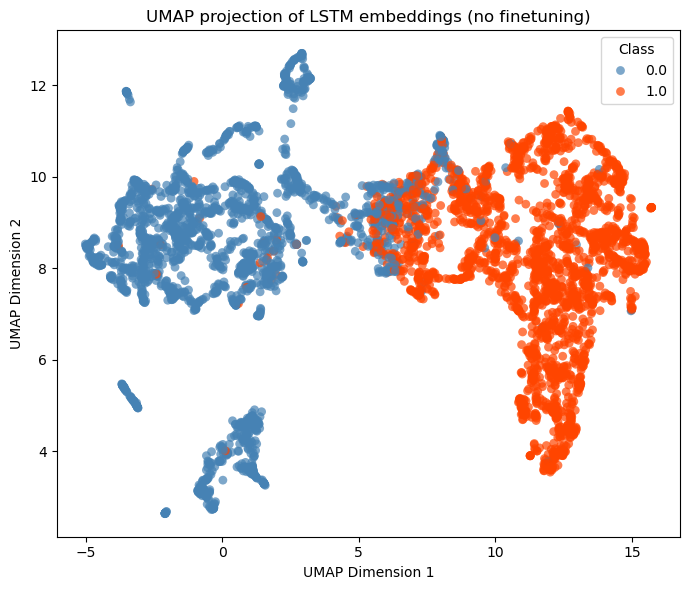

Silhouette Score: 0.601
Latent-space AUC: 0.994
Adjusted Rand Index: 0.788
Between/Within Distance Ratio: 2.733


In [64]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime
from torch.utils.tensorboard import SummaryWriter

# LSTM Classifier (same as before)
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=False,
            dropout=dropout if num_layers > 1 else 0  # LSTM dropout applies only between layers
        )

        # Dropout after LSTM (even if 1 layer)
        self.dropout = nn.Dropout(dropout)

        # Fully connected classifier
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        packed_output, (hn, cn) = self.lstm(packed_input)

        # Get the last hidden state from the last layer
        last_hidden = hn[-1]  # shape: [batch_size, hidden_dim]

        # Apply dropout
        dropped = self.dropout(last_hidden)

        # Fully connected + sigmoid
        out = self.fc(dropped)       # shape: [batch_size, 1]
        out = self.sigmoid(out).squeeze(1)  # shape: [batch_size]
        return out

# Function to freeze the encoder (LSTM)
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Evaluation function with detailed output
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0
    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    # print(f"\nFinal Evaluation on Best Model:")
    # print(f"Accuracy: {acc:.4f}, AUC: {auc:.4f}")
    # print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")
    # print(f"Confusion Matrix:\n{cm}")

    return avg_loss, acc, auc

# Optuna objective for BiLSTM transfer
def load_partial_weights(model, checkpoint_path, max_layers=None):
    """
    Load up to `max_layers` compatible layers from a checkpoint into the model.
    If max_layers is None, load all compatible layers.
    """
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()

    # Filter compatible layers
    compatible_items = [
        (k, v) for k, v in pretrained_dict.items()
        if k in model_dict and model_dict[k].shape == v.shape
    ]

    # Limit number of layers to load
    if max_layers is not None:
        compatible_items = compatible_items[:max_layers]

    # Convert list of tuples back to dict
    compatible_dict = dict(compatible_items)

    # Update model state dict
    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model

lstm_best_param = {'hidden_dim': 95, 'num_layers': 1, 'dropout': 0.20287746211724011, 'lr': 0.004396992152527415, 'weight_decay': 3.999214064585909e-05}

model = LSTMClassifier(input_dim=20, hidden_dim=lstm_best_param['hidden_dim'], num_layers=lstm_best_param['num_layers'], dropout=lstm_best_param['dropout'])
model.load_state_dict(torch.load('weights/best_model_lstm_1.pt'))
# model = load_partial_weights(model, 'best_model_lstm_1.pt', 6)
model.eval()
features, labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        out, (hidden, _) = model.lstm(x)
        # choose the final hidden state or attention output
        features.append(hidden[-1].cpu().numpy())
        labels.extend(y.cpu().numpy())

features = np.vstack(features)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, roc_auc_score, adjusted_rand_score, pairwise_distances
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
import umap.umap_ as umap  # correct import for umap-learn

# -------------------------------------------------------------------
# features: np.ndarray of shape (n_samples, n_features)
# labels: 1D list or array (0 = non-AMP, 1 = TB-AMP)
# -------------------------------------------------------------------

# --- Step 1. Dimensionality reduction --------------------------------
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)
embedding = reducer.fit_transform(features)

# --- Step 2. Plot the embeddings -------------------------------------
plt.figure(figsize=(7,6))
palette = {0: 'steelblue', 1: 'orangered'}
sns.scatterplot(
    x=embedding[:,0],
    y=embedding[:,1],
    hue=labels,
    palette=palette,
    alpha=0.7,
    s=40,
    edgecolor='none'
)
plt.title("UMAP projection of LSTM embeddings (no finetuning)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
# plt.legend(title="Class", labels=["Non-AMP", "TB-AMP"])
plt.legend(title="Class", loc="best")

plt.tight_layout()
plt.show()

# --- Step 3. Quantify separability -----------------------------------
# Silhouette score
sil = silhouette_score(features, labels, metric='cosine')

# Latent-space AUC (linear separability)
clf = LogisticRegression(max_iter=1000)
clf.fit(features, labels)
probs = clf.predict_proba(features)[:,1]
auc = roc_auc_score(labels, probs)

# Cluster alignment (ARI)
preds = KMeans(n_clusters=2, random_state=42).fit_predict(features)
ari = adjusted_rand_score(labels, preds)

# Between/within distance ratio
D = pairwise_distances(features, metric='cosine')
same = D[np.array(labels)[:, None] == np.array(labels)]
diff = D[np.array(labels)[:, None] != np.array(labels)]
ratio = diff.mean() / same.mean()

print(f"Silhouette Score: {sil:.3f}")
print(f"Latent-space AUC: {auc:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")
print(f"Between/Within Distance Ratio: {ratio:.3f}")




/mnt/storageG1/lwang/miniconda3/envs/tb_amp_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


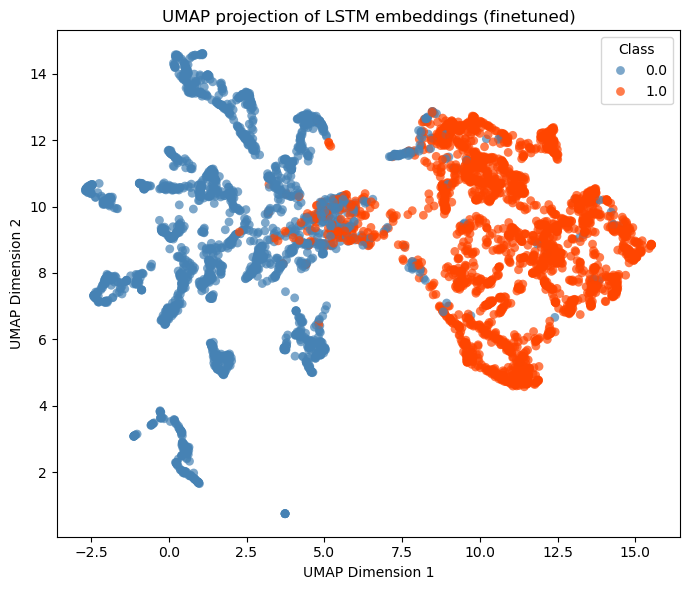

Silhouette Score: 0.620
Latent-space AUC: 0.994
Adjusted Rand Index: 0.829
Between/Within Distance Ratio: 2.824


In [63]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime
from torch.utils.tensorboard import SummaryWriter

# LSTM Classifier (same as before)
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=False,
            dropout=dropout if num_layers > 1 else 0  # LSTM dropout applies only between layers
        )

        # Dropout after LSTM (even if 1 layer)
        self.dropout = nn.Dropout(dropout)

        # Fully connected classifier
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        packed_output, (hn, cn) = self.lstm(packed_input)

        # Get the last hidden state from the last layer
        last_hidden = hn[-1]  # shape: [batch_size, hidden_dim]

        # Apply dropout
        dropped = self.dropout(last_hidden)

        # Fully connected + sigmoid
        out = self.fc(dropped)       # shape: [batch_size, 1]
        out = self.sigmoid(out).squeeze(1)  # shape: [batch_size]
        return out

# Function to freeze the encoder (LSTM)
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Evaluation function with detailed output
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0
    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    # print(f"\nFinal Evaluation on Best Model:")
    # print(f"Accuracy: {acc:.4f}, AUC: {auc:.4f}")
    # print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")
    # print(f"Confusion Matrix:\n{cm}")

    return avg_loss, acc, auc

# Optuna objective for BiLSTM transfer
def load_partial_weights(model, checkpoint_path, max_layers=None):
    """
    Load up to `max_layers` compatible layers from a checkpoint into the model.
    If max_layers is None, load all compatible layers.
    """
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()

    # Filter compatible layers
    compatible_items = [
        (k, v) for k, v in pretrained_dict.items()
        if k in model_dict and model_dict[k].shape == v.shape
    ]

    # Limit number of layers to load
    if max_layers is not None:
        compatible_items = compatible_items[:max_layers]

    # Convert list of tuples back to dict
    compatible_dict = dict(compatible_items)

    # Update model state dict
    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model

lstm_best_param = {'hidden_dim': 95, 'num_layers': 1, 'dropout': 0.20287746211724011, 'lr': 0.004396992152527415, 'weight_decay': 3.999214064585909e-05}

model = LSTMClassifier(input_dim=20, hidden_dim=lstm_best_param['hidden_dim'], num_layers=lstm_best_param['num_layers'], dropout=lstm_best_param['dropout'])
model.load_state_dict(torch.load('weights/best_model_lstm_frozen.pt'))
# model = load_partial_weights(model, 'best_model_lstm_1.pt', 6)
model.eval()
features, labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        out, (hidden, _) = model.lstm(x)
        # choose the final hidden state or attention output
        features.append(hidden[-1].cpu().numpy())
        labels.extend(y.cpu().numpy())

features = np.vstack(features)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, roc_auc_score, adjusted_rand_score, pairwise_distances
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
import umap.umap_ as umap  # correct import for umap-learn

# -------------------------------------------------------------------
# features: np.ndarray of shape (n_samples, n_features)
# labels: 1D list or array (0 = non-AMP, 1 = TB-AMP)
# -------------------------------------------------------------------

# --- Step 1. Dimensionality reduction --------------------------------
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)
embedding = reducer.fit_transform(features)

# --- Step 2. Plot the embeddings -------------------------------------
plt.figure(figsize=(7,6))
palette = {0: 'steelblue', 1: 'orangered'}
sns.scatterplot(
    x=embedding[:,0],
    y=embedding[:,1],
    hue=labels,
    palette=palette,
    alpha=0.7,
    s=40,
    edgecolor='none'
)
plt.title("UMAP projection of LSTM embeddings (finetuned)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
# plt.legend(title="Class", labels=["Non-AMP", "TB-AMP"])
plt.legend(title="Class", loc="best")

plt.tight_layout()
plt.show()

# --- Step 3. Quantify separability -----------------------------------
# Silhouette score
sil = silhouette_score(features, labels, metric='cosine')

# Latent-space AUC (linear separability)
clf = LogisticRegression(max_iter=1000)
clf.fit(features, labels)
probs = clf.predict_proba(features)[:,1]
auc = roc_auc_score(labels, probs)

# Cluster alignment (ARI)
preds = KMeans(n_clusters=2, random_state=42).fit_predict(features)
ari = adjusted_rand_score(labels, preds)

# Between/within distance ratio
D = pairwise_distances(features, metric='cosine')
same = D[np.array(labels)[:, None] == np.array(labels)]
diff = D[np.array(labels)[:, None] != np.array(labels)]
ratio = diff.mean() / same.mean()

print(f"Silhouette Score: {sil:.3f}")
print(f"Latent-space AUC: {auc:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")
print(f"Between/Within Distance Ratio: {ratio:.3f}")

In [51]:
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    print(f"\nFinal Evaluation on Best Model:")
    print(f"Accuracy: {acc:.4f}, AUC: {auc:.4f}")
    print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")
    print(f"Confusion Matrix:\n{cm}")

    return avg_loss, acc, auc

def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm-trans-frozen/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss

# Best hyperparameters: {'lr': 0.009940295438316211, 'weight_decay': 1.4383289881186473e-05, 'dropout': 0.22563027249521914}

model = LSTMClassifier(input_dim=20, hidden_dim=lstm_best_param['hidden_dim'], num_layers=lstm_best_param['num_layers'], dropout=lstm_frozen_best_param['dropout'])
# model.load_state_dict(torch.load('best_model_lstm_1.pt')) 
model = load_partial_weights(model, 'best_model_lstm_1.pt')

freeze_encoder(model)

history = train_model(model, train_loader, val_loader, num_epochs=20, lr=lstm_frozen_best_param['lr'],
                      weight_decay=lstm_frozen_best_param['weight_decay'], verbose=True)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

✅ Loaded 6 matching layers from checkpoint.

Final Evaluation on Best Model:
Accuracy: 0.8750, AUC: 0.9507
Sensitivity: 0.9512, Specificity: 0.8085
Confusion Matrix:
[[38  9]
 [ 2 39]]
Epoch [1/20] - Train Loss: 0.4952, Val Loss: 0.3414, Val Acc: 0.8750, Val AUC: 0.9507

Final Evaluation on Best Model:
Accuracy: 0.8864, AUC: 0.9543
Sensitivity: 0.9512, Specificity: 0.8298
Confusion Matrix:
[[39  8]
 [ 2 39]]
Epoch [2/20] - Train Loss: 0.4296, Val Loss: 0.3117, Val Acc: 0.8864, Val AUC: 0.9543

Final Evaluation on Best Model:
Accuracy: 0.8864, AUC: 0.9574
Sensitivity: 0.9512, Specificity: 0.8298
Confusion Matrix:
[[39  8]
 [ 2 39]]
Epoch [3/20] - Train Loss: 0.4275, Val Loss: 0.2913, Val Acc: 0.8864, Val AUC: 0.9574

Final Evaluation on Best Model:
Accuracy: 0.8864, AUC: 0.9590
Sensitivity: 0.9512, Specificity: 0.8298
Confusion Matrix:
[[39  8]
 [ 2 39]]
Epoch [4/20] - Train Loss: 0.3775, Val Loss: 0.2791, Val Acc: 0.8864, Val AUC: 0.9590

Final Evaluation on Best Model:
Accuracy: 0.897

In [52]:
import numpy as np
import contextlib
import os
import sys

# Helper to suppress prints
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Metrics
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMClassifier(
        input_dim=20,
        hidden_dim=lstm_best_param['hidden_dim'],
        num_layers=lstm_best_param['num_layers'],
        dropout=lstm_frozen_best_param['dropout']
    )
    model = load_partial_weights(model, 'best_model_lstm_1.pt')
    freeze_encoder(model)

    # Suppress stdout during training/evaluation
    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=lstm_frozen_best_param['lr'],
            weight_decay=lstm_frozen_best_param['weight_decay'],
            verbose=False
        )
        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Manually calculate confusion matrix
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Store metrics
    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Print summary
print("\n📊 Summary across runs:")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")


🔁 Run 1/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 2/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 3/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 4/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 5/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 6/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 7/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 8/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 9/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 10/10
✅ Loaded 6 matching layers from checkpoint.

📊 Summary across runs:
Accuracy:       0.9045 ± 0.0056
AUC:            0.9690 ± 0.0002
Sensitivity:    0.9244 ± 0.0073
Specificity:    0.8872 ± 0.0098


In [20]:
## dimension reduction

#### full backprop

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime
from torch.utils.tensorboard import SummaryWriter

# LSTM Classifier (same as before)
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=False,
            dropout=dropout if num_layers > 1 else 0  # LSTM dropout applies only between layers
        )

        # Dropout after LSTM (even if 1 layer)
        self.dropout = nn.Dropout(dropout)

        # Fully connected classifier
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        packed_output, (hn, cn) = self.lstm(packed_input)

        # Get the last hidden state from the last layer
        last_hidden = hn[-1]  # shape: [batch_size, hidden_dim]

        # Apply dropout
        dropped = self.dropout(last_hidden)

        # Fully connected + sigmoid
        out = self.fc(dropped)       # shape: [batch_size, 1]
        out = self.sigmoid(out).squeeze(1)  # shape: [batch_size]
        return out


# Function to freeze the encoder (LSTM)
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Evaluation function with detailed output
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    # print(f"\nFinal Evaluation on Best Model:")
    # print(f"Accuracy: {acc:.4f}, AUC: {auc:.4f}")
    # print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")
    # print(f"Confusion Matrix:\n{cm}")

    return avg_loss, acc, auc

# Training function for frozen encoder
def train_finetune_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                         device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)

    best_val_loss = 1000.0
    log_dir = f"runs-lstm-transfer-fullbackprop/fullbackprop_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=False)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        # if val_auc > best_val_auc:
        #     best_val_auc = val_auc
        #     torch.save(model.state_dict(), 'best_model_frozen.pt')
            
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model_lstm_full_backprop.pt')

    writer.close()
    return best_val_loss

# # Load the best pretrained model and fine-tune
# def finetune_with_frozen_encoder(pretrained_model_path, train_loader, val_loader, hidden_dim, num_layers, dropout):
#     model = LSTMClassifier(input_dim=20, hidden_dim=hidden_dim, num_layers=num_layers, dropout=dropout)
#     model.load_state_dict(torch.load(pretrained_model_path))
#     # freeze_encoder(model)

#     best_auc = train_finetune_model(
#         model=model,
#         train_loader=train_loader,
#         val_loader=val_loader,
#         num_epochs=10,
#         lr=1e-3,
#         weight_decay=1e-4
#     )

#     model.load_state_dict(torch.load('best_model_frozen.pt'))
#     evaluate_model(model, val_loader, nn.BCELoss())

#     return model, best_auc

# model, best_auc = finetune_with_frozen_encoder(
#     pretrained_model_path='best_model-lstm.pt',
#     train_loader=train_loader,
#     val_loader=val_loader,
#     hidden_dim=47,  # or from Optuna
#     num_layers=2,
#     dropout=0.3
# )


# lstm_best_param = {'hidden_dim': 74,
#  'num_layers': 3,
#  'dropout': 0.3037059572844035,
#  'lr': 0.00774103421243492,
#  'weight_decay': 2.4221276513292614e-05}

import optuna

def objective(trial):
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)

    model = LSTMClassifier(input_dim=20, hidden_dim=lstm_best_param['hidden_dim'], num_layers=lstm_best_param['num_layers'], dropout=dropout)
    model.load_state_dict(torch.load('best_model_lstm_1.pt'))
    # freeze_encoder(model)

    return train_finetune_model(
        model, train_loader, val_loader,
        num_epochs=15, lr=lr, weight_decay=weight_decay
    )

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
print("Best hyperparameters:", study.best_trial.params)
lstm_fullbackprop_best_param = study.best_trial.params


[I 2025-04-29 22:10:55,717] A new study created in memory with name: no-name-aed5ef02-5b53-40e1-ba2f-1e7b3602bf3e
[I 2025-04-29 22:10:59,473] Trial 0 finished with value: 0.21000881989796957 and parameters: {'lr': 0.003638914711863913, 'weight_decay': 1.908177732451063e-06, 'dropout': 0.10566476075698641}. Best is trial 0 with value: 0.21000881989796957.
[I 2025-04-29 22:11:03,125] Trial 1 finished with value: 0.2008835350473722 and parameters: {'lr': 0.0022261021284847387, 'weight_decay': 0.004372737378638452, 'dropout': 0.171167212301504}. Best is trial 1 with value: 0.2008835350473722.
[I 2025-04-29 22:11:06,760] Trial 2 finished with value: 0.5003370443979899 and parameters: {'lr': 1.782791261327648e-05, 'weight_decay': 2.9545661586020474e-05, 'dropout': 0.243207621630648}. Best is trial 1 with value: 0.2008835350473722.
[I 2025-04-29 22:11:10,419] Trial 3 finished with value: 0.20486789445082346 and parameters: {'lr': 0.0017625842351926672, 'weight_decay': 0.00038375384209343716, 

Best hyperparameters: {'lr': 0.0032156567293269668, 'weight_decay': 0.007051238524047399, 'dropout': 0.45440393197543916}


In [53]:
lstm_fullbackprop_best_param = {'lr': 0.0032156567293269668, 'weight_decay': 0.007051238524047399, 'dropout': 0.45440393197543916}


In [ ]:
import random
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Optional: For workers in DataLoader
    def seed_worker(worker_id):
        worker_seed = torch.initial_seed() % 2**32
        np.random.seed(worker_seed)
        random.seed(worker_seed)

    g = torch.Generator()
    g.manual_seed(seed)

    return seed_worker, g



def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 1000.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    print(f"\nFinal Evaluation on Best Model:")
    print(f"Accuracy: {acc:.4f}, AUC: {auc:.4f}")
    print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")
    print(f"Confusion Matrix:\n{cm}")

    return avg_loss, acc, auc



def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    if not train:
        model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss

# Best hyperparameters: {'lr': 0.008986542560528932, 'weight_decay': 2.3033044758439348e-06, 'dropout': 0.17164705350229123}

model = LSTMClassifier(input_dim=20, hidden_dim=113, num_layers=1, dropout=lstm_fullbackprop_best_param['dropout'])
history = train_model(model, train_loader, val_loader, num_epochs=19, lr=lstm_fullbackprop_best_param['lr'],
                      weight_decay=lstm_fullbackprop_best_param['weight_decay'], verbose=True, train=False)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")


In [58]:

import numpy as np
import contextlib
import os
import sys

# Helper to suppress prints
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Metrics
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMClassifier(input_dim=20, hidden_dim=113, num_layers=1, dropout=lstm_fullbackprop_best_param['dropout'])


    # Suppress stdout during training and evaluation
    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=lstm_fullbackprop_best_param['lr'],
            weight_decay=lstm_fullbackprop_best_param['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Manually calculate confusion matrix
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Store metrics
    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Print summary
print("\n📊 Summary across runs (Full Backpropagation Model):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10

🔁 Run 2/10

🔁 Run 3/10

🔁 Run 4/10

🔁 Run 5/10

🔁 Run 6/10

🔁 Run 7/10

🔁 Run 8/10

🔁 Run 9/10

🔁 Run 10/10

📊 Summary across runs (Full Backpropagation Model):
Accuracy:       0.8091 ± 0.0484
AUC:            0.8649 ± 0.0548
Sensitivity:    0.7415 ± 0.0749
Specificity:    0.8681 ± 0.0886


### BiLSTM

#### frozen

#### running repeats, accounting for stochastic results

In [91]:
bilstm_frozen_best_parameters = {'lr': 0.009981673641982228,
 'weight_decay': 1.5244563205828208e-06,
 'dropout': 0.38560031839200354}

bilstm_best_param = {'hidden_dim': 59, 'num_layers': 1, 'dropout': 0.19595557432276017, 'lr': 0.009816503475479747, 'weight_decay': 2.600777275437832e-05}

/mnt/storageG1/lwang/miniconda3/envs/tb_amp_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


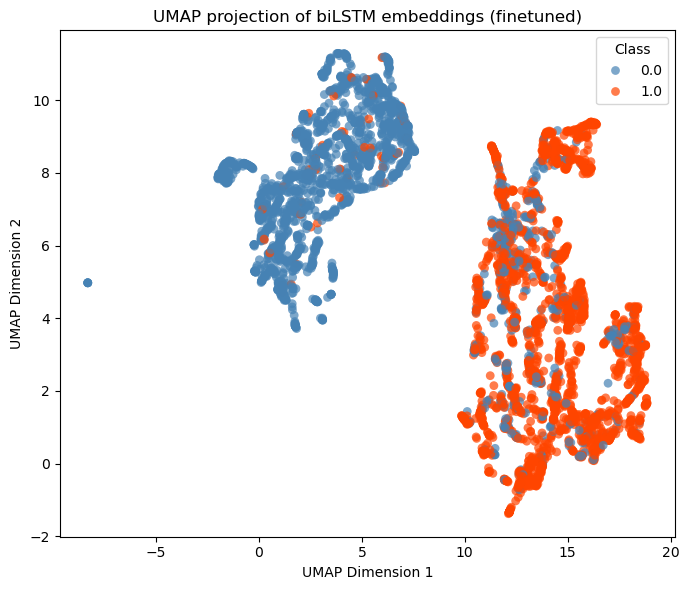

Silhouette Score: 0.211
Latent-space AUC: 0.948
Adjusted Rand Index: 0.414
Between/Within Distance Ratio: 1.283


In [41]:
class BiLSTMWithFlattenClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3, max_seq_len=100):
        super(BiLSTMWithFlattenClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.max_seq_len = max_seq_len

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(max_seq_len * hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        batch_size, seq_len, feature_dim = lstm_out.size()

        if seq_len < self.max_seq_len:
            pad_len = self.max_seq_len - seq_len
            pad = torch.zeros(batch_size, pad_len, feature_dim, device=lstm_out.device)
            lstm_out = torch.cat([lstm_out, pad], dim=1)
        elif seq_len > self.max_seq_len:
            lstm_out = lstm_out[:, :self.max_seq_len, :]

        dropped = self.dropout(lstm_out)
        flat = dropped.contiguous().view(batch_size, -1)
        out = self.fc(flat)
        return self.sigmoid(out).squeeze(1)

# Freeze encoder

# model = LSTMClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=bilstm_frozen_best_parameters['dropout'])
bilstm_fullbackprop_best_parameters = {'lr': 0.00926595862633317, 'weight_decay': 2.0121744840074475e-05, 'dropout': 0.46616976355966055}
bilstm_best_param = {'hidden_dim': 59, 'num_layers': 1, 'dropout': 0.19595557432276017, 'lr': 0.009816503475479747, 'weight_decay': 2.600777275437832e-05}
bilstm_frozen_best_parameters = {'lr': 0.009981673641982228,
 'weight_decay': 1.5244563205828208e-06,
 'dropout': 0.38560031839200354}
model = BiLSTMWithFlattenClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=bilstm_fullbackprop_best_parameters['dropout'], max_seq_len=100)
# model = BiLSTMWithFlattenClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=bilstm_frozen_best_parameters['dropout'], max_seq_len=100)
# model.load_state_dict(torch.load('weights/best_model_bilstm_frozen.pt'))
model.load_state_dict(torch.load('weights/best_model_bilstm_fullbackprop.pt'))

# model = load_partial_weights(model, 'best_model_lstm_1.pt', 6)
model.eval()
features, labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        out, (hidden, _) = model.lstm(x)
        # choose the final hidden state or attention output
        features.append(hidden[-1].cpu().numpy())
        labels.extend(y.cpu().numpy())

features = np.vstack(features)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, roc_auc_score, adjusted_rand_score, pairwise_distances
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
import umap.umap_ as umap  # correct import for umap-learn

# -------------------------------------------------------------------
# features: np.ndarray of shape (n_samples, n_features)
# labels: 1D list or array (0 = non-AMP, 1 = TB-AMP)
# -------------------------------------------------------------------

# --- Step 1. Dimensionality reduction --------------------------------
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)
embedding = reducer.fit_transform(features)

# --- Step 2. Plot the embeddings -------------------------------------
plt.figure(figsize=(7,6))
palette = {0: 'steelblue', 1: 'orangered'}
sns.scatterplot(
    x=embedding[:,0],
    y=embedding[:,1],
    hue=labels,
    palette=palette,
    alpha=0.7,
    s=40,
    edgecolor='none'
)
plt.title("UMAP projection of biLSTM embeddings (finetuned)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
# plt.legend(title="Class", labels=["Non-AMP", "TB-AMP"])
plt.legend(title="Class", loc="best")
plt.tight_layout()
plt.show()

# --- Step 3. Quantify separability -----------------------------------
# Silhouette score
sil = silhouette_score(features, labels, metric='cosine')

# Latent-space AUC (linear separability)
clf = LogisticRegression(max_iter=1000)
clf.fit(features, labels)
probs = clf.predict_proba(features)[:,1]
auc = roc_auc_score(labels, probs)

# Cluster alignment (ARI)
preds = KMeans(n_clusters=2, random_state=42).fit_predict(features)
ari = adjusted_rand_score(labels, preds)

# Between/within distance ratio
D = pairwise_distances(features, metric='cosine')
same = D[np.array(labels)[:, None] == np.array(labels)]
diff = D[np.array(labels)[:, None] != np.array(labels)]
ratio = diff.mean() / same.mean()

print(f"Silhouette Score: {sil:.3f}")
print(f"Latent-space AUC: {auc:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")
print(f"Between/Within Distance Ratio: {ratio:.3f}")

/mnt/storageG1/lwang/miniconda3/envs/tb_amp_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


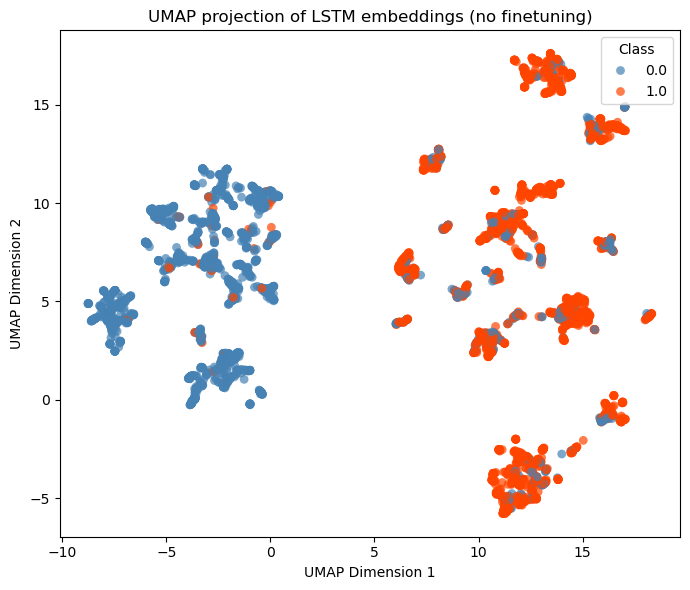

Silhouette Score: 0.195
Latent-space AUC: 0.942
Adjusted Rand Index: 0.582
Between/Within Distance Ratio: 1.234


In [42]:
class BiLSTMWithFlattenClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3, max_seq_len=100):
        super(BiLSTMWithFlattenClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.max_seq_len = max_seq_len

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(max_seq_len * hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        batch_size, seq_len, feature_dim = lstm_out.size()

        if seq_len < self.max_seq_len:
            pad_len = self.max_seq_len - seq_len
            pad = torch.zeros(batch_size, pad_len, feature_dim, device=lstm_out.device)
            lstm_out = torch.cat([lstm_out, pad], dim=1)
        elif seq_len > self.max_seq_len:
            lstm_out = lstm_out[:, :self.max_seq_len, :]

        dropped = self.dropout(lstm_out)
        flat = dropped.contiguous().view(batch_size, -1)
        out = self.fc(flat)
        return self.sigmoid(out).squeeze(1)

# Freeze encoder

# model = LSTMClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=bilstm_frozen_best_parameters['dropout'])
bilstm_best_param = {'hidden_dim': 59, 'num_layers': 1, 'dropout': 0.19595557432276017, 'lr': 0.009816503475479747, 'weight_decay': 2.600777275437832e-05}

model = BiLSTMWithFlattenClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=bilstm_frozen_best_parameters['dropout'], max_seq_len=100)
model.load_state_dict(torch.load('weights/best_model_bilstm_frozen.pt'))

# model = load_partial_weights(model, 'best_model_lstm_1.pt', 6)
model.eval()
features, labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        out, (hidden, _) = model.lstm(x)
        # choose the final hidden state or attention output
        features.append(hidden[-1].cpu().numpy())
        labels.extend(y.cpu().numpy())

features = np.vstack(features)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, roc_auc_score, adjusted_rand_score, pairwise_distances
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
import umap.umap_ as umap  # correct import for umap-learn

# -------------------------------------------------------------------
# features: np.ndarray of shape (n_samples, n_features)
# labels: 1D list or array (0 = non-AMP, 1 = TB-AMP)
# -------------------------------------------------------------------

# --- Step 1. Dimensionality reduction --------------------------------
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)
embedding = reducer.fit_transform(features)

# --- Step 2. Plot the embeddings -------------------------------------
plt.figure(figsize=(7,6))
palette = {0: 'steelblue', 1: 'orangered'}
sns.scatterplot(
    x=embedding[:,0],
    y=embedding[:,1],
    hue=labels,
    palette=palette,
    alpha=0.7,
    s=40,
    edgecolor='none'
)
plt.title("UMAP projection of LSTM embeddings (no finetuning)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
# plt.legend(title="Class", labels=["Non-AMP", "TB-AMP"])
plt.legend(title="Class", loc="best")
plt.tight_layout()
plt.show()

# --- Step 3. Quantify separability -----------------------------------
# Silhouette score
sil = silhouette_score(features, labels, metric='cosine')

# Latent-space AUC (linear separability)
clf = LogisticRegression(max_iter=1000)
clf.fit(features, labels)
probs = clf.predict_proba(features)[:,1]
auc = roc_auc_score(labels, probs)

# Cluster alignment (ARI)
preds = KMeans(n_clusters=2, random_state=42).fit_predict(features)
ari = adjusted_rand_score(labels, preds)

# Between/within distance ratio
D = pairwise_distances(features, metric='cosine')
same = D[np.array(labels)[:, None] == np.array(labels)]
diff = D[np.array(labels)[:, None] != np.array(labels)]
ratio = diff.mean() / same.mean()

print(f"Silhouette Score: {sil:.3f}")
print(f"Latent-space AUC: {auc:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")
print(f"Between/Within Distance Ratio: {ratio:.3f}")

In [94]:
import numpy as np
import contextlib
import os
import sys

# Helper to suppress prints
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Metrics
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = BiLSTMWithFlattenClassifier(
        input_dim=20,
        hidden_dim=bilstm_best_param['hidden_dim'],
        num_layers=bilstm_best_param['num_layers'],
        dropout=bilstm_frozen_best_parameters['dropout'],
        max_seq_len=100
    )

    model = load_partial_weights(model, 'best_model-bilstm.pt', 6)
    freeze_encoder(model, 6)

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=bilstm_frozen_best_parameters['lr'],
            weight_decay=bilstm_frozen_best_parameters['weight_decay'],
            verbose=False,
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Calculate sensitivity and specificity
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Store metrics
    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Print summary
print("\n📊 Summary across runs (BiLSTM with Flatten & Frozen Encoder):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 2/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 3/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 4/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 5/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 6/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 7/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 8/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 9/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

🔁 Run 10/10
✅ Loaded 6 matching layers from checkpoint.
✅ Frozen first 6 LSTM layers.

📊 Summary across runs (BiLSTM with Flatten & Frozen Encoder):
Accuracy:       0.8920 ± 0.0205
AUC:            0.9584 ± 0.0093
Sensitivity:

In [25]:
import numpy as np
import contextlib
import os
import sys

# Helper to suppress prints
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Metrics
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = BiLSTMWithFlattenClassifier(
        input_dim=20,
        hidden_dim=bilstm_best_param['hidden_dim'],
        num_layers=bilstm_best_param['num_layers'],
        dropout=bilstm_frozen_best_parameters['dropout'],
        max_seq_len=100
    )

    model = load_partial_weights(model, 'best_model-bilstm.pt', 3)
    freeze_encoder(model, 3)

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=bilstm_frozen_best_parameters['lr'],
            weight_decay=bilstm_frozen_best_parameters['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Calculate sensitivity and specificity
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Store metrics
    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Print summary
print("\n📊 Summary across runs (BiLSTM with Flatten & Frozen Encoder):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 2/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 3/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 4/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 5/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 6/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 7/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 8/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 9/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

🔁 Run 10/10
✅ Loaded 3 matching layers from checkpoint.
✅ Frozen first 3 LSTM layers.

📊 Summary across runs (BiLSTM with Flatten & Frozen Encoder):
Accuracy:       0.8886 ± 0.0287
AUC:            0.9514 ± 0.0097
Sensitivity:

#### full backprop

In [71]:

# Updated BiLSTM with Flatten Transfer Learning
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime
from torch.utils.tensorboard import SummaryWriter
import optuna
class BiLSTMWithFlattenClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3, max_seq_len=100):
        super(BiLSTMWithFlattenClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.max_seq_len = max_seq_len

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(max_seq_len * hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        batch_size, seq_len, feature_dim = lstm_out.size()

        if seq_len < self.max_seq_len:
            pad_len = self.max_seq_len - seq_len
            pad = torch.zeros(batch_size, pad_len, feature_dim, device=lstm_out.device)
            lstm_out = torch.cat([lstm_out, pad], dim=1)
        elif seq_len > self.max_seq_len:
            lstm_out = lstm_out[:, :self.max_seq_len, :]

        dropped = self.dropout(lstm_out)
        flat = dropped.contiguous().view(batch_size, -1)
        out = self.fc(flat)
        return self.sigmoid(out).squeeze(1)

# Freeze encoder

def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Evaluation

def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0
    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    return avg_loss, acc, auc

# Training for fine-tuning

def train_finetune_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                         device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)

    best_val_loss = 1000
    log_dir = f"runs-bilstm-trans-fullbackprop/BiLSTMTransfer_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=False)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model_bilstm_fullbackprop.pt')

    writer.close()
    return best_val_loss

# Optuna objective for BiLSTM transfer
def load_partial_weights(model, checkpoint_path):
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()

    compatible_dict = {
        k: v for k, v in pretrained_dict.items()
        if k in model_dict and model_dict[k].shape == v.shape
    }

    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model


def load_partial_weights(model, checkpoint_path, max_layers=None):
    """
    Load up to `max_layers` compatible layers from a checkpoint into the model.
    If max_layers is None, load all compatible layers.
    """
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()

    # Filter compatible layers
    compatible_items = [
        (k, v) for k, v in pretrained_dict.items()
        if k in model_dict and model_dict[k].shape == v.shape
    ]

    # Limit number of layers to load
    if max_layers is not None:
        compatible_items = compatible_items[:max_layers]

    # Convert list of tuples back to dict
    compatible_dict = dict(compatible_items)

    # Update model state dict
    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model

def objective(trial):
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)

    model = BiLSTMWithFlattenClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=dropout, max_seq_len=100)
    # model.load_state_dict(torch.load('best_model-bilstm.pt'))
    model = load_partial_weights(model, 'best_model-bilstm.pt', 6)

    # freeze_encoder(model)

    return train_finetune_model(
        model, train_loader, val_loader,
        num_epochs=20, lr=lr, weight_decay=weight_decay
    )

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
print("Best hyperparameters:", study.best_trial.params)
bilstm_fullbackprop_best_parameters = study.best_trial.params

[I 2025-04-30 17:30:22,477] A new study created in memory with name: no-name-55b57740-d999-48bf-bfc7-ed8bf7f76410


✅ Loaded 6 matching layers from checkpoint.


[I 2025-04-30 17:30:28,751] Trial 0 finished with value: 0.6472770969072977 and parameters: {'lr': 2.7468020893093288e-05, 'weight_decay': 1.9823888137898948e-05, 'dropout': 0.3614048468861061}. Best is trial 0 with value: 0.6472770969072977.


✅ Loaded 6 matching layers from checkpoint.


[I 2025-04-30 17:30:34,951] Trial 1 finished with value: 0.5378240942955017 and parameters: {'lr': 0.00011050232434267229, 'weight_decay': 0.002430591078406706, 'dropout': 0.44456875419188324}. Best is trial 1 with value: 0.5378240942955017.


...

✅ Loaded 6 matching layers from checkpoint.


[I 2025-04-30 17:32:33,702] Trial 18 finished with value: 0.3766237248977025 and parameters: {'lr': 0.004245728608577005, 'weight_decay': 3.8442241149315545e-06, 'dropout': 0.4758037419174857}. Best is trial 6 with value: 0.31085051223635674.


✅ Loaded 6 matching layers from checkpoint.


[I 2025-04-30 17:32:42,339] Trial 19 finished with value: 0.40634193023045856 and parameters: {'lr': 0.0005770924461404385, 'weight_decay': 5.446901693669708e-05, 'dropout': 0.3651356881275941}. Best is trial 6 with value: 0.31085051223635674.


Best hyperparameters: {'lr': 0.00926595862633317, 'weight_decay': 2.0121744840074475e-05, 'dropout': 0.46616976355966055}


In [33]:
bilstm_fullbackprop_best_parameters = {'lr': 0.00926595862633317, 'weight_decay': 2.0121744840074475e-05, 'dropout': 0.46616976355966055}

In [34]:
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc


def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    if not train:
        model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss


# to rerun
model = BiLSTMWithFlattenClassifier(input_dim=20, hidden_dim=bilstm_best_param['hidden_dim'], num_layers=bilstm_best_param['num_layers'], dropout=bilstm_frozen_best_parameters['dropout'], max_seq_len=100)
# model = load_partial_weights(model, 'best_model-bilstm.pt')
model = load_partial_weights(model, 'best_model-bilstm.pt', 6)

# freeze_encoder(model)

history = train_model(model, train_loader, val_loader, num_epochs=10, lr=bilstm_fullbackprop_best_parameters['lr'],
                      weight_decay=bilstm_fullbackprop_best_parameters['weight_decay'], verbose=True, train=False)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

✅ Loaded 6 matching layers from checkpoint.



Confusion Matrix:
[[39  8]
 [ 7 34]]
Sensitivity: 0.8293, Specificity: 0.8298
Epoch [1/10] - Train Loss: 0.5627, Val Loss: 0.4075, Val Acc: 0.8295, Val AUC: 0.9045

Confusion Matrix:
[[44  3]
 [ 9 32]]
Sensitivity: 0.7805, Specificity: 0.9362
Epoch [2/10] - Train Loss: 0.2654, Val Loss: 0.3568, Val Acc: 0.8636, Val AUC: 0.9382

Confusion Matrix:
[[33 14]
 [ 1 40]]
Sensitivity: 0.9756, Specificity: 0.7021
Epoch [3/10] - Train Loss: 0.1702, Val Loss: 0.4432, Val Acc: 0.8295, Val AUC: 0.9403

Confusion Matrix:
[[44  3]
 [ 8 33]]
Sensitivity: 0.8049, Specificity: 0.9362
Epoch [4/10] - Train Loss: 0.1447, Val Loss: 0.3491, Val Acc: 0.8750, Val AUC: 0.9481

Confusion Matrix:
[[39  8]
 [ 5 36]]
Sensitivity: 0.8780, Specificity: 0.8298
Epoch [5/10] - Train Loss: 0.0804, Val Loss: 0.3542, Val Acc: 0.8523, Val AUC: 0.9502

Confusion Matrix:
[[43  4]
 [ 6 35]]
Sensitivity: 0.8537, Specificity: 0.9149
Epoch [6/10] - Train Loss: 0.0486, Val Loss: 0.3847, Val Acc: 0.8864, Val AUC: 0.9523

Confusion

In [35]:
import numpy as np
import contextlib
import os
import sys

# Suppress stdout context manager
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Metric containers
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = BiLSTMWithFlattenClassifier(
        input_dim=20,
        hidden_dim=bilstm_best_param['hidden_dim'],
        num_layers=bilstm_best_param['num_layers'],
        dropout=bilstm_frozen_best_parameters['dropout'],
        max_seq_len=100
    )
    model = load_partial_weights(model, 'best_model-bilstm.pt', 6)
    # Not freezing encoder (full backprop setting)

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=bilstm_fullbackprop_best_parameters['lr'],
            weight_decay=bilstm_fullbackprop_best_parameters['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Calculate confusion matrix for sensitivity/specificity
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Store metrics
    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Print results
print("\n📊 Summary across runs (BiLSTM + Flatten, Full Backprop):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 2/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 3/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 4/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 5/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 6/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 7/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 8/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 9/10
✅ Loaded 6 matching layers from checkpoint.

🔁 Run 10/10
✅ Loaded 6 matching layers from checkpoint.

📊 Summary across runs (BiLSTM + Flatten, Full Backprop):
Accuracy:       0.8750 ± 0.0114
AUC:            0.9441 ± 0.0071
Sensitivity:    0.8098 ± 0.0146
Specificity:    0.9319 ± 0.0208


### lstm + attention

#### frozen

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import datetime
import optuna
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
from torch.utils.tensorboard import SummaryWriter

# LSTM with Attention
class LSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMWithAttentionClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=False
        )

        self.dropout = nn.Dropout(dropout)
        self.attn = nn.Linear(hidden_dim, 1)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        attn_weights = self.attn(lstm_out).squeeze(-1)
        attn_weights = torch.softmax(attn_weights, dim=1)
        attn_applied = torch.sum(lstm_out * attn_weights.unsqueeze(-1), dim=1)

        dropped = self.dropout(attn_applied)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)

# Freeze LSTM encoder
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Evaluation
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    return avg_loss, acc, auc

# Training
def train_finetune_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                         device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)

    best_val_loss = float('inf')
    log_dir = f"runs-lstm-att-trans/LSTMAttTransfer_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=False)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model_lstm_att_frozen.pt')

    writer.close()
    return best_val_loss

# Load compatible weights
def load_partial_weights(model, checkpoint_path):
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()
    compatible_dict = {k: v for k, v in pretrained_dict.items() if k in model_dict and model_dict[k].shape == v.shape}
    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model

# Freeze LSTM encoder
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Optuna objective
def objective(trial):
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)

    model = LSTMWithAttentionClassifier(input_dim=20, hidden_dim=69, num_layers=2, dropout=dropout)
    model = load_partial_weights(model, 'best_model-lstm_attention.pt')
    freeze_encoder(model)

    return train_finetune_model(
        model, train_loader, val_loader,
        num_epochs=15, lr=lr, weight_decay=weight_decay
    )

# Run optimization
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=12)

print("Best hyperparameters:", study.best_trial.params)
lstm_att_frozen_best_parameters = study.best_trial.params

[I 2025-04-30 15:43:21,490] A new study created in memory with name: no-name-a7d840e6-6b44-4aac-bb65-e37e9b4eab81


✅ Loaded 2 matching layers from checkpoint.


[I 2025-04-30 15:43:25,753] Trial 0 finished with value: 0.7674408356348673 and parameters: {'lr': 0.0013602003194664756, 'weight_decay': 1.5712677101296663e-05, 'dropout': 0.4169138472289945}. Best is trial 0 with value: 0.7674408356348673.


✅ Loaded 2 matching layers from checkpoint.


[I 2025-04-30 15:43:30,111] Trial 1 finished with value: 0.895917534828186 and parameters: {'lr': 0.00013430607061839717, 'weight_decay': 0.0042018236062449435, 'dropout': 0.15353305409980217}. Best is trial 0 with value: 0.7674408356348673.


...

✅ Loaded 2 matching layers from checkpoint.


[I 2025-04-30 15:44:07,962] Trial 10 finished with value: 0.6912072499593099 and parameters: {'lr': 0.009315794991764154, 'weight_decay': 1.3701958442320686e-06, 'dropout': 0.26912897628898586}. Best is trial 10 with value: 0.6912072499593099.


✅ Loaded 2 matching layers from checkpoint.


[I 2025-04-30 15:44:12,344] Trial 11 finished with value: 0.691220243771871 and parameters: {'lr': 0.009073800913924703, 'weight_decay': 1.3122066920704696e-06, 'dropout': 0.27779103538774164}. Best is trial 10 with value: 0.6912072499593099.


Best hyperparameters: {'lr': 0.009315794991764154, 'weight_decay': 1.3701958442320686e-06, 'dropout': 0.26912897628898586}


In [36]:
lstm_att_frozen_best_parameters = {'lr': 0.009315794991764154,
 'weight_decay': 1.3701958442320686e-06,
 'dropout': 0.26912897628898586}

lstm_attn_best_param = {'hidden_dim': 85, 'num_layers': 1, 'dropout': 0.4548453210586073, 'lr': 0.005881852254528488, 'weight_decay': 1.22922875003128e-06}

In [37]:
class LSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMWithAttentionClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=False
        )

        self.dropout = nn.Dropout(dropout)
        self.attn = nn.Linear(hidden_dim, 1)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        attn_weights = self.attn(lstm_out).squeeze(-1)
        attn_weights = torch.softmax(attn_weights, dim=1)
        attn_applied = torch.sum(lstm_out * attn_weights.unsqueeze(-1), dim=1)

        dropped = self.dropout(attn_applied)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)

def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc

def load_partial_weights(model, checkpoint_path):
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()
    compatible_dict = {k: v for k, v in pretrained_dict.items() if k in model_dict and model_dict[k].shape == v.shape}
    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model

# Freeze LSTM encoder
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    if not train:
        model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss

# to rerun
model = LSTMWithAttentionClassifier(input_dim=20, hidden_dim=69, num_layers=2, dropout=lstm_att_frozen_best_parameters['dropout'])
model = load_partial_weights(model, 'best_model-lstm_attention.pt')
freeze_encoder(model)

history = train_model(model, train_loader, val_loader, num_epochs=20, lr=lstm_att_frozen_best_parameters['lr'],
                      weight_decay=lstm_att_frozen_best_parameters['weight_decay'], verbose=True, train=False)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

✅ Loaded 2 matching layers from checkpoint.

Confusion Matrix:
[[ 0 47]
 [ 0 41]]
Sensitivity: 1.0000, Specificity: 0.0000
Epoch [1/20] - Train Loss: 0.8567, Val Loss: 0.8225, Val Acc: 0.4659, Val AUC: 0.5605

Confusion Matrix:
[[ 0 47]
 [ 0 41]]
Sensitivity: 1.0000, Specificity: 0.0000
Epoch [2/20] - Train Loss: 0.7898, Val Loss: 0.7654, Val Acc: 0.4659, Val AUC: 0.5856

Confusion Matrix:
[[ 0 47]
 [ 0 41]]
Sensitivity: 1.0000, Specificity: 0.0000
Epoch [3/20] - Train Loss: 0.7341, Val Loss: 0.7288, Val Acc: 0.4659, Val AUC: 0.6082

Confusion Matrix:
[[ 0 47]
 [ 0 41]]
Sensitivity: 1.0000, Specificity: 0.0000
Epoch [4/20] - Train Loss: 0.7150, Val Loss: 0.7072, Val Acc: 0.4659, Val AUC: 0.6209

Confusion Matrix:
[[ 0 47]
 [ 0 41]]
Sensitivity: 1.0000, Specificity: 0.0000
Epoch [5/20] - Train Loss: 0.7011, Val Loss: 0.6962, Val Acc: 0.4659, Val AUC: 0.6321

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [6/20] - Train Loss: 0.6903, Val Loss: 0.6923,

In [38]:

import numpy as np
import contextlib
import os
import sys

# Suppress print helper
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Number of repeated runs
n_runs = 10

# Containers for metrics
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=69,
        num_layers=2,
        dropout=lstm_att_frozen_best_parameters['dropout']
    )
    model = load_partial_weights(model, 'best_model-lstm_attention.pt')
    freeze_encoder(model)

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=lstm_att_frozen_best_parameters['lr'],
            weight_decay=lstm_att_frozen_best_parameters['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Gather predictions for confusion matrix
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Report results
print("\n📊 Summary across runs (LSTM + Attention, Frozen Encoder):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 2/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 3/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 4/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 5/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 6/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 7/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 8/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 9/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 10/10
✅ Loaded 2 matching layers from checkpoint.

📊 Summary across runs (LSTM + Attention, Frozen Encoder):
Accuracy:       0.5341 ± 0.0000
AUC:            0.5960 ± 0.0725
Sensitivity:    0.0000 ± 0.0000
Specificity:    1.0000 ± 0.0000


#### full back prop

In [39]:
import torch
import torch.nn as nn
import torch.optim as optim
import datetime
import optuna
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
from torch.utils.tensorboard import SummaryWriter

# LSTM with Attention
class LSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(LSTMWithAttentionClassifier, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=False
        )

        self.dropout = nn.Dropout(dropout)
        self.attn = nn.Linear(hidden_dim, 1)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        attn_weights = self.attn(lstm_out).squeeze(-1)
        attn_weights = torch.softmax(attn_weights, dim=1)
        attn_applied = torch.sum(lstm_out * attn_weights.unsqueeze(-1), dim=1)

        dropped = self.dropout(attn_applied)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)

# Freeze LSTM encoder
def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False

# Evaluation
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')

    return avg_loss, acc, auc

# Training
def train_finetune_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4,
                         device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)

    best_val_loss = float('inf')
    log_dir = f"runs-lstm-att-trans-fullback/LSTMAttTransfer_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=False)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model_lstm_att_fullbackprop.pt')

    writer.close()
    return best_val_loss

# Load compatible weights
def load_partial_weights(model, checkpoint_path):
    pretrained_dict = torch.load(checkpoint_path, map_location='cpu')
    model_dict = model.state_dict()
    compatible_dict = {k: v for k, v in pretrained_dict.items() if k in model_dict and model_dict[k].shape == v.shape}
    model_dict.update(compatible_dict)
    model.load_state_dict(model_dict)
    print(f"✅ Loaded {len(compatible_dict)} matching layers from checkpoint.")
    return model

# Optuna objective
def objective(trial):
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.5)

    model = LSTMWithAttentionClassifier(input_dim=20, hidden_dim=69, num_layers=2, dropout=dropout)
    model = load_partial_weights(model, 'best_model-lstm_attention.pt')
    # freeze_encoder(model)

    return train_finetune_model(
        model, train_loader, val_loader,
        num_epochs=25, lr=lr, weight_decay=weight_decay
    )

# Run optimization
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=12)

print("Best hyperparameters:", study.best_trial.params)
lstm_att_fullbackprop_best_parameters = study.best_trial.params

[I 2025-05-07 12:29:47,068] A new study created in memory with name: no-name-a0000a5b-72b6-41a8-ba1c-5f00adfeaa80


✅ Loaded 2 matching layers from checkpoint.


[I 2025-05-07 12:29:53,712] Trial 0 finished with value: 0.6914660930633545 and parameters: {'lr': 0.0029967656533688865, 'weight_decay': 0.0049030752646570955, 'dropout': 0.3250483615260311}. Best is trial 0 with value: 0.6914660930633545.


✅ Loaded 2 matching layers from checkpoint.


[I 2025-05-07 12:30:00,138] Trial 1 finished with value: 0.5183326800664266 and parameters: {'lr': 0.0014579455447640487, 'weight_decay': 0.0010401727921543593, 'dropout': 0.4730567117660187}. Best is trial 1 with value: 0.5183326800664266.


...

✅ Loaded 2 matching layers from checkpoint.


[I 2025-05-07 12:30:59,169] Trial 10 finished with value: 0.6913865407307943 and parameters: {'lr': 0.007371039933080636, 'weight_decay': 0.008559837751342328, 'dropout': 0.4969806330878609}. Best is trial 6 with value: 0.3559575279553731.


✅ Loaded 2 matching layers from checkpoint.


[I 2025-05-07 12:31:05,611] Trial 11 finished with value: 0.4573590159416199 and parameters: {'lr': 0.008620030197543878, 'weight_decay': 2.358389060728292e-06, 'dropout': 0.38682571951887923}. Best is trial 6 with value: 0.3559575279553731.


Best hyperparameters: {'lr': 0.0021165182290548107, 'weight_decay': 0.0010480406121951673, 'dropout': 0.4671789599752957}


In [40]:
lstm_att_fullbackprop_best_parameters =  {'lr': 0.003661950605748677, 'weight_decay': 1.6001438653977643e-06, 'dropout': 0.4778793892133558}

In [41]:
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc



def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    if not train:
        model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-lstm/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss

model = LSTMWithAttentionClassifier(input_dim=20, hidden_dim=69, num_layers=2, dropout=lstm_att_fullbackprop_best_parameters['dropout'])
model = load_partial_weights(model, 'best_model-lstm_attention.pt')

history = train_model(model, train_loader, val_loader, num_epochs=20, lr=lstm_att_fullbackprop_best_parameters['lr'],
                      weight_decay=lstm_att_fullbackprop_best_parameters['weight_decay'], verbose=True, train=False)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

✅ Loaded 2 matching layers from checkpoint.

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [1/20] - Train Loss: 0.7897, Val Loss: 0.6935, Val Acc: 0.5341, Val AUC: 0.4966

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [2/20] - Train Loss: 0.6995, Val Loss: 0.6905, Val Acc: 0.5341, Val AUC: 0.5874

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [3/20] - Train Loss: 0.6956, Val Loss: 0.6891, Val Acc: 0.5341, Val AUC: 0.6570

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [4/20] - Train Loss: 0.7015, Val Loss: 0.6875, Val Acc: 0.5341, Val AUC: 0.7120

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [5/20] - Train Loss: 0.6934, Val Loss: 0.6840, Val Acc: 0.5341, Val AUC: 0.7442

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [6/20] - Train Loss: 0.6697, Val Loss: 0.7072,

In [42]:
import numpy as np
import contextlib
import os
import sys
import optuna

# Suppress print helper
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout


n_runs = 10
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=69,
        num_layers=2,
        dropout=lstm_att_fullbackprop_best_parameters['dropout']
    )

    model = load_partial_weights(model, 'best_model-lstm_attention.pt')  # adjust if needed

    with suppress_stdout():
        train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=lstm_att_fullbackprop_best_parameters['lr'],
            weight_decay=lstm_att_fullbackprop_best_parameters['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

print("\n📊 Summary across runs (LSTM + Attention, Full Backprop):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 2/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 3/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 4/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 5/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 6/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 7/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 8/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 9/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 10/10
✅ Loaded 2 matching layers from checkpoint.

📊 Summary across runs (LSTM + Attention, Full Backprop):
Accuracy:       0.8273 ± 0.0396
AUC:            0.9144 ± 0.0187
Sensitivity:    0.7780 ± 0.0941
Specificity:    0.8702 ± 0.1285


### BiLSTM + attention

/mnt/storageG1/lwang/miniconda3/envs/tb_amp_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


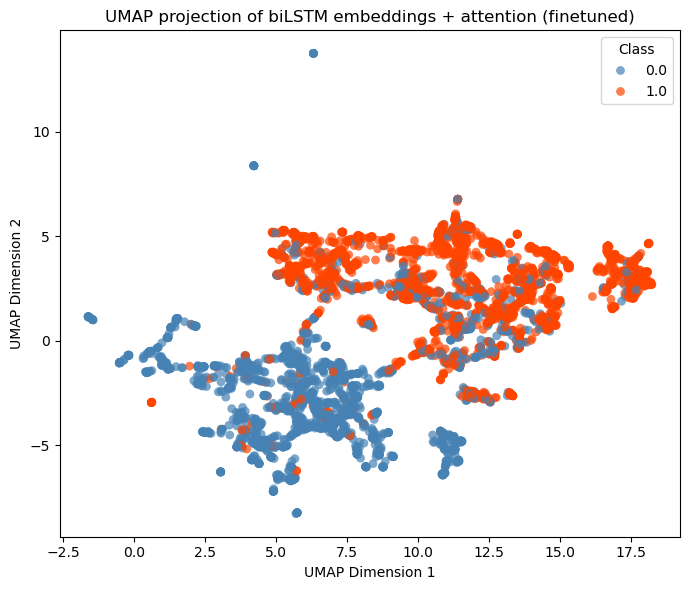

Silhouette Score: 0.123
Latent-space AUC: 0.912
Adjusted Rand Index: 0.094
Between/Within Distance Ratio: 1.134


In [59]:
# Updated BiLSTM with Flatten Transfer Learning
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from torch.nn.utils.rnn import pad_packed_sequence
import datetime
from torch.utils.tensorboard import SummaryWriter
import optuna

class BiLSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(BiLSTMWithAttentionClassifier, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        # Attention mechanism
        attn_weights = torch.softmax(self.attention(lstm_out), dim=1)
        context_vector = torch.sum(attn_weights * lstm_out, dim=1)

        dropped = self.dropout(context_vector)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)
# Freeze encoder

bilstm_attn_best_param = {'hidden_dim': 33, 'num_layers': 2, 'dropout': 0.10065981308640495, 'lr': 0.009726729721310196, 'weight_decay': 1.9050323459033188e-05}

model = BiLSTMWithAttentionClassifier(input_dim=20, hidden_dim=bilstm_attn_best_param['hidden_dim'], num_layers=bilstm_attn_best_param['num_layers'], dropout=bilstm_attn_best_param['dropout'])
model.load_state_dict(torch.load('weights/best_model_bilstm_attn_fullbackprop.pt'))
# model.load_state_dict(model, 'weights/best_model-bilstm_attention_tb.pt')


# model = load_partial_weights(model, 'best_model_lstm_1.pt', 6)
model.eval()
features, labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        out, (hidden, _) = model.lstm(x)
        # choose the final hidden state or attention output
        features.append(hidden[-1].cpu().numpy())
        labels.extend(y.cpu().numpy())

features = np.vstack(features)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, roc_auc_score, adjusted_rand_score, pairwise_distances
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
import umap.umap_ as umap  # correct import for umap-learn

# -------------------------------------------------------------------
# features: np.ndarray of shape (n_samples, n_features)
# labels: 1D list or array (0 = non-AMP, 1 = TB-AMP)
# -------------------------------------------------------------------

# --- Step 1. Dimensionality reduction --------------------------------
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)
embedding = reducer.fit_transform(features)

# --- Step 2. Plot the embeddings -------------------------------------
plt.figure(figsize=(7,6))
palette = {0: 'steelblue', 1: 'orangered'}
sns.scatterplot(
    x=embedding[:,0],
    y=embedding[:,1],
    hue=labels,
    palette=palette,
    alpha=0.7,
    s=40,
    edgecolor='none'
)
plt.title("UMAP projection of biLSTM embeddings + attention (finetuned)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
# plt.legend(title="Class", labels=["Non-AMP", "TB-AMP"])
plt.legend(title="Class", loc="best")
plt.tight_layout()
plt.show()

# --- Step 3. Quantify separability -----------------------------------
# Silhouette score
sil = silhouette_score(features, labels, metric='cosine')

# Latent-space AUC (linear separability)
clf = LogisticRegression(max_iter=1000)
clf.fit(features, labels)
probs = clf.predict_proba(features)[:,1]
auc = roc_auc_score(labels, probs)

# Cluster alignment (ARI)
preds = KMeans(n_clusters=2, random_state=42).fit_predict(features)
ari = adjusted_rand_score(labels, preds)

# Between/within distance ratio
D = pairwise_distances(features, metric='cosine')
same = D[np.array(labels)[:, None] == np.array(labels)]
diff = D[np.array(labels)[:, None] != np.array(labels)]
ratio = diff.mean() / same.mean()

print(f"Silhouette Score: {sil:.3f}")
print(f"Latent-space AUC: {auc:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")
print(f"Between/Within Distance Ratio: {ratio:.3f}")

#### frozen

In [43]:
bilstm_attn_best_param = {'hidden_dim': 33, 'num_layers': 2, 'dropout': 0.10065981308640495, 'lr': 0.009726729721310196, 'weight_decay': 1.9050323459033188e-05}
bilstm_attn_frozen_best_parameters = {'lr': 0.001603372192461072, 'weight_decay': 2.7392594780050672e-05, 'dropout': 0.35549236639803505}

In [44]:
class BiLSTMWithAttentionClassifier(nn.Module):
    def __init__(self, input_dim=20, hidden_dim=64, num_layers=1, dropout=0.3):
        super(BiLSTMWithAttentionClassifier, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, packed_input):
        unpacked, lengths = pad_packed_sequence(packed_input, batch_first=True)
        lstm_out, _ = self.lstm(unpacked)

        # Attention mechanism
        attn_weights = torch.softmax(self.attention(lstm_out), dim=1)
        context_vector = torch.sum(attn_weights * lstm_out, dim=1)

        dropped = self.dropout(context_vector)
        out = self.fc(dropped)
        return self.sigmoid(out).squeeze(1)
# Freeze encoder

def freeze_encoder(model):
    for name, param in model.named_parameters():
        if 'lstm' in name:
            param.requires_grad = False


def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc


def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    if not train:
        model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-bilstm_attn-trans-frozen/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss

# to rerun
model = BiLSTMWithAttentionClassifier(input_dim=20, hidden_dim=bilstm_attn_best_param['hidden_dim'], num_layers=bilstm_attn_best_param['num_layers'], dropout=bilstm_attn_frozen_best_parameters['dropout'])
model = load_partial_weights(model, 'best_model-bilstm_attention.pt')
freeze_encoder(model)

history = train_model(model, train_loader, val_loader, num_epochs=50, lr=bilstm_attn_frozen_best_parameters['lr'],
                      weight_decay=bilstm_attn_frozen_best_parameters['weight_decay'], verbose=True, train=False)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

✅ Loaded 2 matching layers from checkpoint.

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [1/50] - Train Loss: 0.6932, Val Loss: 0.6918, Val Acc: 0.5341, Val AUC: 0.3944

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [2/50] - Train Loss: 0.6909, Val Loss: 0.6915, Val Acc: 0.5341, Val AUC: 0.4058

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [3/50] - Train Loss: 0.6900, Val Loss: 0.6915, Val Acc: 0.5341, Val AUC: 0.4214

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [4/50] - Train Loss: 0.6925, Val Loss: 0.6915, Val Acc: 0.5341, Val AUC: 0.4424

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [5/50] - Train Loss: 0.6885, Val Loss: 0.6914, Val Acc: 0.5341, Val AUC: 0.4567

Confusion Matrix:
[[47  0]
 [41  0]]
Sensitivity: 0.0000, Specificity: 1.0000
Epoch [6/50] - Train Loss: 0.6945, Val Loss: 0.6914,

In [45]:
import numpy as np
import contextlib
import os
import sys

# Suppress print helper
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Run settings
n_runs = 10
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = LSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=69,
        num_layers=2,
        dropout=lstm_att_fullbackprop_best_parameters['dropout']
    )
    model = load_partial_weights(model, 'best_model-lstm_attention.pt')

    with suppress_stdout():
        history = train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=lstm_att_fullbackprop_best_parameters['lr'],
            weight_decay=lstm_att_fullbackprop_best_parameters['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Compute confusion matrix metrics
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Summary
print("\n📊 Summary across 10 runs (LSTM + Attention, Full Backprop, no freezing):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")



🔁 Run 1/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 2/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 3/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 4/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 5/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 6/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 7/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 8/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 9/10
✅ Loaded 2 matching layers from checkpoint.

🔁 Run 10/10
✅ Loaded 2 matching layers from checkpoint.

📊 Summary across 10 runs (LSTM + Attention, Full Backprop, no freezing):
Accuracy:       0.8102 ± 0.0536
AUC:            0.8917 ± 0.0455
Sensitivity:    0.8707 ± 0.0994
Specificity:    0.7574 ± 0.1750


#### full back prop

In [46]:
bilstm_attn_fullbackprop_best_parameters = {'lr': 0.004843097327507198, 'weight_decay': 0.0006598357188430301, 'dropout': 0.49558732282929335}

In [ ]:
def evaluate_model(model, data_loader, criterion, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    with torch.no_grad():
        for packed_input, labels in data_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(outputs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
    acc = accuracy_score(all_labels, pred_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        auc = float('nan')

    cm = confusion_matrix(all_labels, pred_labels)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    if verbose:
        print(f"\nConfusion Matrix:\n{cm}")
        print(f"Sensitivity: {sensitivity:.4f}, Specificity: {specificity:.4f}")

    return avg_loss, acc, auc


def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-3, weight_decay=1e-4, device='cuda' if torch.cuda.is_available() else 'cpu', verbose=False, train=False):
    model.to(device)
    if not train:
        model.eval()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_loss = 1000

    log_dir = f"runs-bilstm_attn-trans-fullbackprop/AMP_LSTM_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
    writer = SummaryWriter(log_dir=log_dir)

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for packed_input, labels in train_loader:
            labels = labels.to(device)
            packed_input = packed_input.to(device)

            optimizer.zero_grad()
            outputs = model(packed_input)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        val_loss, val_acc, val_auc = evaluate_model(model, val_loader, criterion, device, verbose=verbose)

        writer.add_scalar('Loss/Train', avg_train_loss, epoch)
        writer.add_scalar('Loss/Validation', val_loss, epoch)
        writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        writer.add_scalar('AUC/Validation', val_auc, epoch)

        if verbose:
            print(f"Epoch [{epoch}/{num_epochs}] - "
                  f"Train Loss: {avg_train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, "
                  f"Val Acc: {val_acc:.4f}, "
                  f"Val AUC: {val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            if train:
                torch.save(model.state_dict(), 'best_model_lstm.pt')

    writer.close()
    return best_val_loss

model = BiLSTMWithAttentionClassifier(input_dim=20, hidden_dim=bilstm_attn_best_param['hidden_dim'], num_layers=bilstm_attn_best_param['num_layers'], dropout=bilstm_attn_fullbackprop_best_parameters['dropout'])
model = load_partial_weights(model, 'best_model-bilstm_attention.pt')
freeze_encoder(model)

history = train_model(model, train_loader, val_loader, num_epochs=120, lr=bilstm_attn_fullbackprop_best_parameters['lr'],
                      weight_decay=bilstm_attn_fullbackprop_best_parameters['weight_decay'], verbose=True, train=False)

criterion = nn.BCELoss()
val_loss, val_acc, val_auc = evaluate_model(model, test_loader, criterion, verbose=True)
print(f"Test Loss: {val_loss:.4f}, Test Accuracy: {val_acc:.4f}, Test AUC: {val_auc:.4f}")

import numpy as np
import contextlib
import os
import sys

# Helper: suppress printing
@contextlib.contextmanager
def suppress_stdout():
    with open(os.devnull, "w") as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

# Metrics storage
n_runs = 10
acc_list, auc_list, sens_list, spec_list = [], [], [], []

for run in range(n_runs):
    print(f"\n🔁 Run {run + 1}/{n_runs}")

    model = BiLSTMWithAttentionClassifier(
        input_dim=20,
        hidden_dim=bilstm_best_param['hidden_dim'],
        num_layers=bilstm_best_param['num_layers'],
        dropout=bilstm_attn_fullbackprop_best_parameters['dropout']
    )
    model = load_partial_weights(model, 'best_model-bilstm.pt')

    with suppress_stdout():
        history = train_model(
            model, train_loader, val_loader,
            num_epochs=25,
            lr=bilstm_attn_fullbackprop_best_parameters['lr'],
            weight_decay=bilstm_attn_fullbackprop_best_parameters['weight_decay'],
            verbose=False,
            train=False
        )

        criterion = nn.BCELoss()
        val_loss, acc, auc = evaluate_model(model, test_loader, criterion, verbose=False)

        # Manually compute confusion matrix
        model.eval()
        all_labels, all_preds = [], []
        with torch.no_grad():
            for packed_input, labels in test_loader:
                packed_input = packed_input.to(model.fc.weight.device)
                labels = labels.to(model.fc.weight.device)
                outputs = model(packed_input)
                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(outputs.cpu().numpy())

        pred_labels = [1 if p > 0.5 else 0 for p in all_preds]
        cm = confusion_matrix(all_labels, pred_labels)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    acc_list.append(acc)
    auc_list.append(auc)
    sens_list.append(sens)
    spec_list.append(spec)

# Print summary
print("\n📊 Summary across 10 runs (BiLSTM + Attention, Full Backprop):")
print(f"Accuracy:       {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"AUC:            {np.mean(auc_list):.4f} ± {np.std(auc_list):.4f}")
print(f"Sensitivity:    {np.mean(sens_list):.4f} ± {np.std(sens_list):.4f}")
print(f"Specificity:    {np.mean(spec_list):.4f} ± {np.std(spec_list):.4f}")
